# 04 — Prétraitement

Ce notebook explique et justifie les choix de prétraitement de House Prices. Les règles réutilisables sont importées depuis `src/preprocessing/`. Nous partons des anomalies et des distributions observées à l’[étape 3](03_analyse_exploratoire.ipynb).

## 1. Protocole

Dans les CSV, `NA` signale une valeur absente. Le mot `None` est un code valide, notamment pour une maison sans parement de maçonnerie. Nous désactivons donc les autres marqueurs de valeurs manquantes de pandas.

Nous définissons une partition de 80 % des ventes pour l’entraînement et de 20 % pour la validation (`random_state=42`). Pour comparer les choix de nettoyage, nous utilisons une validation croisée à cinq plis sur les 1 460 ventes étiquetées. La comparaison de la section 2.6 utilise les prédictions hors pli de toutes les ventes. La partition 20 % recoupe ces plis et ne constitue donc pas un test indépendant de ce choix. Tout paramètre appris, dont les médianes et les coefficients du modèle, provient des seules maisons d’entraînement du pli. Le fichier Kaggle `test.csv` sert ici à compter et illustrer les corrections.

La partition réserve 292 ventes sur 1 460. En validation croisée, chacune des 1 460 maisons reçoit une seule prédiction hors pli.

**Ventes typiques.** Les scores de comparaison sont calculés sur les **ventes typiques** : toutes les ventes sauf les deux ventes aberrantes de la section 2.6 (maisons 524 et 1299). Ces deux ventes sont retirées de l’entraînement de chaque pli.

In [8]:
from pathlib import Path
import inspect

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV
from sklearn.model_selection import KFold, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (
    FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler,
)

from src.evaluation import cv_rmse, rmse_log
from src.preprocessing.steps.cleaning import Cleaner, LARGE_HOUSE_AREA, remove_outliers
from src.preprocessing.steps.encoding import (
    ORDINAL_COLUMNS, QUALITY_COLUMNS, RARE_CATEGORY_MIN_COUNT, QualityOrdinalEncoder,
    make_onehot_encoder, nominal_columns,
)
from src.preprocessing.steps.features import AGE_FEATURES, SUM_FEATURES, FeatureCreator
from src.preprocessing.steps.missing import (
    EQUIPMENT_GROUPS, NO_MEASURE_ABSENCE, MissingValueHandler, consistency_report,
)
from src.preprocessing.steps.scaling import NO_LOG_COLUMNS, SkewCorrector, make_scaler
from src.preprocessing.pipelines import (
    RECIPES, make_base, make_causal, make_causal_pca, make_correlation, make_pca,
)
from src.preprocessing.strategies.causal import CONSEQUENCES, DUPLICATES, causal_drops


def show_title(title):
    """Afficher dans les sorties le titre de la sous-section correspondante du texte."""
    display(Markdown(f"**{title}**"))

# ──────────────────────────────────────────────────────────────────────
# 1 · Données et partition
# ──────────────────────────────────────────────────────────────────────
show_title("1 · Données et partition")
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
read_options = {"na_values": ["NA"], "keep_default_na": False}
train = pd.read_csv(root / "data/train.csv", **read_options)
test = pd.read_csv(root / "data/test.csv", **read_options)
X, y = train.drop(columns="SalePrice"), train["SalePrice"]
train_index, holdout_index = train_test_split(X.index, test_size=0.2, random_state=42)
folds = KFold(n_splits=5, shuffle=True, random_state=42)
print(f"Partition 80/20 : {len(train_index)} maisons d’entraînement et {len(holdout_index)} de validation.")

**1 · Données et partition**

Partition 80/20 : 1168 maisons d’entraînement et 292 de validation.


## 2. Nettoyage

Nous corrigeons les erreurs manifestes et marquons comme inconnue toute information contradictoire dont la valeur correcte nous échappe. L’imputation relève de la section 3. Une catégorie rare peut encore décrire des maisons différentes. La section 7 évaluera l’intérêt prédictif des variables conservées.

### Doublons et identifiant

Un identifiant unique pourrait masquer des doublons descriptifs. Nous vérifions séparément les identifiants, les lignes complètes et les caractéristiques seules.

Aucun identifiant ni aucune ligne complète ne se répète dans train. Nous gardons les ventes et retirons `Id` des prédicteurs. Nous le conservons dans les tableaux descriptifs pour retrouver chaque maison.

### 2.1 Type de logement

**Problème.** À l’étape 3 (§ 2), `MSSubClass` est lu comme un entier. La sortie « 2.1 Type de logement » regroupe toutes les maisons concernées par code et par fichier.

**Décision.** Convertir le code en texte. **Code.** Règle `MSSubClass` de `Cleaner.transform`.

**Justification.** Le code 20 désigne une maison à un étage construite à partir de 1946, le code 60 une maison à deux étages de la même période, et le code 190 une conversion bifamiliale. Un coefficient appliqué au nombre imposerait un ordre et une distance arbitraires. L’encodage catégoriel pourra aussi traiter le code 150, observé seulement dans test.

### 2.2 Revêtements extérieurs

**Problème.** `Exterior1st` indique le revêtement principal des murs et `Exterior2nd` le revêtement secondaire. L’étape 3 (§ 2) relève trois différences d’orthographe entre ces colonnes.

**Décision.** Employer les codes du revêtement principal pour les deux colonnes. **Code.** Règle `Exterior2nd` de `Cleaner.transform`.

**Justification.** Une maison entièrement en bardeaux de bois pouvait porter à la fois `WdShing` et `Wd Shng`. Une comparaison directe aurait alors compté deux matériaux. La correction conserve l’information sur le matériau.

### 2.3 Services publics et variables quasi constantes

**Problème.** La synthèse de l’étape 3 (§ 8) signale sept variables quasi constantes. Nous comptons les modalités de `Utilities`, y compris les valeurs inconnues, puis examinons les exceptions des six autres variables.

**Décision.** Retirer `Utilities` et conserver les six autres caractéristiques. **Code.** Règle `Utilities` de `Cleaner.transform`.

**Justification.** Une seule maison de train a la modalité `NoSeWa`. Dans test, toutes les modalités renseignées sont `AllPub`. Les autres variables ont des exceptions dans les deux fichiers et les prix médians diffèrent dans train. Les petits effectifs limitent l’interprétation de ces écarts. La section 7 examinera leur intérêt pour la prédiction.

### 2.4 Année du garage

**Problème.** Deux garages de test ont une année postérieure à la vente (étape 3, § 4). La sortie « 2.4 Année du garage » rapproche l’année déclarée du type de garage et des dates de la maison.

**Décision.** Si l’année du garage dépasse celle de la vente de plus d’un an, reprendre l’année de rénovation de cette même maison. **Code.** Règle `GarageYrBlt` de `Cleaner.transform`.

**Justification.** Les ventes vont de 2006 à 2010. L’année 2207 du garage attaché de la maison 2593 est une faute de frappe manifeste. Sa rénovation date de 2007, année plausible que la règle retrouve sans consulter l’identifiant. Kaggle exige une prédiction pour chaque maison de test. Garder la maison, l’existence de son garage et une année approximative préserve l’information disponible. Pour la maison 2550, une vente sur plan en 2007 est compatible avec une construction en 2008. La tolérance d’un an conserve cette date.

### 2.5 Parement de maçonnerie

**Problème.** Le parement est une couche décorative de brique ou de pierre sur une partie des murs extérieurs. `MasVnrType` décrit le matériau et `MasVnrArea` la surface en pi². L’étape 3 (§ 4) signale des contradictions entre les deux. Pour situer leur ordre de grandeur, nous calculons la surface médiane des parements de surface positive et de matériau connu dans train.

**Décision.** Corriger la surface bouche-trou. Pour les autres contradictions, marquer le seul champ douteux comme inconnu. **Code.** Règle `MasVnrType` de `Cleaner.transform`.

**Justification.** Un parement couvre typiquement environ 200 pi². Une surface d’un pied carré pour un parement déclaré absent est une valeur bouche-trou. À l’inverse, plusieurs centaines de pieds carrés rendent le matériau déclaré absent suspect. Quand le matériau est connu et que la surface vaut zéro, c’est la mesure de surface qui manque.

| Cas | Id dans train | Id dans test | Champ probablement faux et correction |
|---|---|---|---|
| Aucun parement, 1 pi² | 774, 1231 | 2453 | Surface bouche-trou ramenée à 0 |
| Aucun parement, surface supérieure à 1 pi² | 625, 1301, 1335 | 1670 | Type inconnu, surface conservée |
| Brique ou pierre, 0 pi² | 689, 1242 | 2320 | Surface inconnue, matériau conservé |

La section 3 devra distinguer ces inconnues créées par le nettoyage des `NA` d’origine lors de l’imputation.

### 2.6 Valeurs aberrantes

Une vente est aberrante lorsque son prix paraît incohérent avec les caractéristiques de la maison. Un prix élevé peut très bien correspondre à une vaste maison de grande qualité. Nous reprenons les quatre grandes maisons du nuage de points de l’étape 3 (§ 5 et § 7.1).

Les maisons 524 et 1299, de qualité 10 à Edwards, se sont vendues moins de 185 000 $ en condition `Partial`. Les deux grandes maisons de NoRidge se sont vendues beaucoup plus cher. Nous comparons le retrait ciblé au retrait par surface seule et au retrait par prix seul.

**Comparaison provisoire.** Un transformateur de pipeline modifie X et doit préserver l’alignement avec y. Nous filtrons donc ensemble X et les prix en dollars **avant** d’ajuster le pipeline, dans la partie entraînement de chaque pli. Toutes les ventes de validation sont prédites.

Les étapes 3 à 7 restent à développer. Pour cette comparaison, nous utilisons uniquement `Cleaner`, une imputation médiane des variables numériques, `log1p` des surfaces (zéro reste défini), une standardisation numérique et un encodage disjonctif des catégories après remplacement provisoire des inconnues par la constante `None`. Les catégories inédites sont ignorées. RidgeCV ajuste une régression ridge sur le logarithme naturel du prix avec 30 pénalisations candidates communes aux quatre options.

Le seuil du 1 % pour l’option D est recalculé sur les prix d’entraînement de chaque pli. Pour les scores, nous rassemblons les prédictions hors pli en dollars. Nous calculons ensuite la RMSE des logarithmes sur toutes les maisons, sur les ventes typiques (sans 524 et 1299, voir la section 1), puis sur les 5 % les plus chères d’après les prix observés. Ce dernier seuil sert uniquement à lire les résultats.

**Interprétation.** Le retrait du centile supérieur (D) prive le modèle de ventes représentatives du haut de gamme. Sur les 5 % les plus chères, l’erreur passe de 0,1772 (A) à 0,1993 (D). Une maison de test dépasse également 4 000 pi², même si son prix est inconnu. B et C sont proches sur toutes les ventes (0,1283 et 0,1276) comme sur les ventes typiques (0,1137 et 0,1136). Sur les ventes typiques, retirer les deux ventes ciblées de l’entraînement réduit nettement l’erreur : 0,1183 pour A contre 0,1137 pour B. B donne la plus faible erreur sur les maisons chères (0,1448 contre 0,1474). Dans le troisième pli, les deux ventes ciblées se trouvent en validation : elles comptent dans la colonne « toutes », mais pas dans la colonne « ventes typiques », qui sert de critère dans la suite du notebook.

**Décision.** Nous retenons B. De Cock conseille pour son jeu pédagogique d’écarter les maisons de plus de 4 000 pi². Il distingue les ventes partielles atypiques des très grandes maisons vendues à un prix cohérent. Sur le train Kaggle, B conserve les deux ventes de NoRidge qui suivent la tendance générale. La section 8 reprendra la comparaison avec la recette complète. [De Cock (2011), *Journal of Statistics Education*, 19(3)](https://doi.org/10.1080/10691898.2011.11889627)

### 2.7 Récapitulatif du nettoyage

Les suppressions de colonnes et la conversion de type concernent chaque ligne. Pour les corrections de valeurs, nous comptons les différences observées entre les données brutes et la sortie de `Cleaner`. La dernière ligne compte le retrait ciblé sur l’ensemble de train à titre descriptif.

Le nettoyage conserve toutes les lignes nécessaires aux prédictions Kaggle. Les contradictions de maçonnerie laissent une information exploitable dans l’autre champ. La prochaine étape traitera les valeurs manquantes en tenant compte de cet indice.

In [9]:
# ──────────────────────────────────────────────────────────────────────
# 2 · Doublons et identifiant
# ──────────────────────────────────────────────────────────────────────
show_title("2 · Doublons et identifiant")
display(pd.Series({
    "Identifiants répétés": train["Id"].duplicated().sum(),
    "Lignes identiques": train.duplicated().sum(),
    "Caractéristiques identiques hors Id et prix": X.drop(columns="Id").duplicated().sum(),
}, name="Répétitions dans train"))
cleaner = Cleaner().fit(X.iloc[train_index])
raw = pd.concat({"train": X, "test": test}, names=["Fichier", "Ligne"])
clean = pd.concat({"train": cleaner.transform(X), "test": cleaner.transform(test)},
                  names=raw.index.names)

def rule_doc(column):
    """Afficher la ligne de documentation correspondant à la règle étudiée."""
    lines = inspect.getdoc(Cleaner.transform).splitlines()
    print("Cleaner.transform —", next(line for line in lines if line.startswith(column + " ")))

def changed(column):
    """Repérer une correction, en considérant deux valeurs manquantes comme identiques."""
    before, after = raw[column], clean[column]
    same = before.eq(after).fillna(False) | (before.isna() & after.isna())
    return ~same


# ──────────────────────────────────────────────────────────────────────
# 2.1 Type de logement
# ──────────────────────────────────────────────────────────────────────
show_title("2.1 Type de logement")
rule_doc("MSSubClass")
display(pd.crosstab(raw["MSSubClass"], raw.index.get_level_values("Fichier")))


# ──────────────────────────────────────────────────────────────────────
# 2.2 Revêtements extérieurs
# ──────────────────────────────────────────────────────────────────────
show_title("2.2 Revêtements extérieurs")
rule_doc("Exterior2nd")
exterior = raw.loc[changed("Exterior2nd"), ["Id", "Exterior1st", "Exterior2nd"]].copy()
exterior["Code harmonisé"] = clean.loc[exterior.index, "Exterior2nd"]
display(exterior.groupby(["Exterior2nd", "Code harmonisé", "Fichier"]).size()
        .unstack("Fichier", fill_value=0))
display(exterior)


# ──────────────────────────────────────────────────────────────────────
# 2.3 Services publics et variables quasi constantes
# ──────────────────────────────────────────────────────────────────────
show_title("2.3 Services publics et variables quasi constantes")
rule_doc("Utilities")
display(pd.crosstab(raw["Utilities"].fillna("Inconnu"), raw.index.get_level_values("Fichier")))
rare_columns = ["Street", "PoolQC", "Condition2", "RoofMatl", "Heating", "MiscFeature"]
rows = []
for column in rare_columns:
    values = train[column].fillna("Absent")
    majority = values.mode().iat[0]
    unusual = values.ne(majority)
    rows.append([column, majority, unusual.sum(), test[column].fillna("Absent").ne(majority).sum(),
                 y[~unusual].median(), y[unusual].median()])
display(pd.DataFrame(rows, columns=["Variable", "Majorité train", "Exceptions train",
                                     "Exceptions test", "Prix médian majorité ($)",
                                     "Prix médian exceptions ($)"]))


# ──────────────────────────────────────────────────────────────────────
# 2.4 Année du garage
# ──────────────────────────────────────────────────────────────────────
show_title("2.4 Année du garage")
rule_doc("GarageYrBlt")
garage = raw.loc[raw["GarageYrBlt"].gt(raw["YrSold"]),
                 ["Id", "GarageType", "GarageYrBlt", "YearBuilt", "YearRemodAdd", "YrSold"]].copy()
garage["Année retenue"] = clean.loc[garage.index, "GarageYrBlt"]
display(garage)


# ──────────────────────────────────────────────────────────────────────
# 2.5 Parement de maçonnerie
# ──────────────────────────────────────────────────────────────────────
show_title("2.5 Parement de maçonnerie")
rule_doc("MasVnrType")
known = train["MasVnrType"].isin(["BrkFace", "BrkCmn", "Stone"]) & train["MasVnrArea"].gt(0)
print(f"Surface médiane des parements renseignés : {train.loc[known, 'MasVnrArea'].median():g} pi²")
area_changed = changed("MasVnrArea")
type_changed = changed("MasVnrType")
placeholder = area_changed & clean["MasVnrArea"].eq(0)
unknown_area = area_changed & clean["MasVnrArea"].isna()
masonry = raw.loc[type_changed | area_changed, ["Id", "MasVnrType", "MasVnrArea"]].copy()
masonry["Type retenu"] = clean.loc[masonry.index, "MasVnrType"]
masonry["Surface retenue"] = clean.loc[masonry.index, "MasVnrArea"]
display(masonry)


# ──────────────────────────────────────────────────────────────────────
# 2.6 Valeurs aberrantes · grandes maisons
# ──────────────────────────────────────────────────────────────────────
show_title("2.6 Valeurs aberrantes · grandes maisons")
display(train.loc[X["GrLivArea"].gt(LARGE_HOUSE_AREA),
                  ["Id", "Neighborhood", "GrLivArea", "OverallQual", "SaleCondition", "SalePrice"]])
print(inspect.getdoc(remove_outliers))


# ──────────────────────────────────────────────────────────────────────
# 2.6 Valeurs aberrantes · modèle provisoire
# ──────────────────────────────────────────────────────────────────────
# Les surfaces sont exprimées en pi² dans le dictionnaire d'Ames.
area_columns = [
    "LotArea", "MasVnrArea", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
    "1stFlrSF", "2ndFlrSF", "LowQualFinSF", "GrLivArea", "GarageArea", "WoodDeckSF",
    "OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch", "PoolArea",
]

def other_numeric(frame):
    """Les autres grandeurs restent sur leur échelle avant standardisation."""
    return frame.select_dtypes(include="number").columns.difference(area_columns).tolist()

def add_garage_flag(frame):
    """Distinguer la présence du garage pour comparer ses années imputées."""
    return frame.assign(HasGarage=frame["GarageArea"].gt(0).astype(int))

def provisional_model(imputer=None):
    """Reprendre les mêmes transformations et le même modèle dans les deux comparaisons."""
    steps = [Cleaner()]
    area_steps = [FunctionTransformer(np.log1p), StandardScaler()]
    numeric = StandardScaler()
    nominal = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    if imputer is None:
        areas = make_pipeline(SimpleImputer(strategy="median"), *area_steps)
        numeric = make_pipeline(SimpleImputer(strategy="median"), numeric)
        nominal = make_pipeline(SimpleImputer(strategy="constant", fill_value="None"), nominal)
    else:
        steps.extend([imputer, FunctionTransformer(add_garage_flag)])
        areas = make_pipeline(*area_steps)
    columns = ColumnTransformer([
        ("areas", areas, area_columns), ("numeric", numeric, other_numeric),
        ("nominal", nominal, make_column_selector(dtype_exclude="number")),
    ])
    return make_pipeline(*steps, columns, RidgeCV(alphas=np.logspace(-1, 3, 30)))


# ──────────────────────────────────────────────────────────────────────
# 2.6 Valeurs aberrantes · comparaison des retraits
# ──────────────────────────────────────────────────────────────────────
show_title("2.6 Valeurs aberrantes · comparaison des retraits")
options = ["A · Tout garder", "B · Retrait ciblé", "C · Surface > 4 000 pi²", "D · Prix du centile supérieur"]
scores = []
for option in options:
    predictions = pd.Series(np.nan, index=y.index)
    removed = []
    for fit_index, valid_index in folds.split(X):
        features, prices = X.iloc[fit_index], y.iloc[fit_index]
        if option == options[1]:
            features, prices = remove_outliers(features, prices)
        elif option == options[2]:
            keep = features["GrLivArea"].le(LARGE_HOUSE_AREA)
            features, prices = features.loc[keep], prices.loc[keep]
        elif option == options[3]:
            keep = prices.le(prices.quantile(0.99))
            features, prices = features.loc[keep], prices.loc[keep]
        removed.append(len(fit_index) - len(features))
        model = provisional_model().fit(features, np.log(prices))
        predictions.iloc[valid_index] = np.exp(model.predict(X.iloc[valid_index]))
    assert predictions.notna().all()
    expensive = y.ge(y.quantile(0.95))
    scores.append([option, removed, rmse_log(y, predictions), cv_rmse(y, predictions, X),
                   rmse_log(y[expensive], predictions[expensive])])

comparison = pd.DataFrame(scores, columns=["Option", "Retraits par pli", "RMSE log · toutes",
                                          "RMSE log · ventes typiques",
                                          "RMSE log · 5 % les plus chères"])
display(comparison.round(4))


# ──────────────────────────────────────────────────────────────────────
# 2.7 Récapitulatif du nettoyage
# ──────────────────────────────────────────────────────────────────────
show_title("2.7 Récapitulatif du nettoyage")
def counts(mask):
    """Compter les maisons concernées dans chacun des deux fichiers."""
    return [int(mask.loc[file].sum()) for file in ("train", "test")]

sizes = [len(train), len(test)]
retained, _ = remove_outliers(X, y)
summary = pd.DataFrame([
    ["Doublons", train.duplicated().sum(), test.duplicated().sum(), "Aucun retrait"],
    ["Id", *sizes, "Retirer la colonne"],
    ["MSSubClass", *sizes, "Convertir en texte"],
    ["Exterior2nd", *counts(changed("Exterior2nd")), "Harmoniser trois codes"],
    ["Utilities", *sizes, "Retirer la colonne"],
    ["GarageYrBlt", *counts(changed("GarageYrBlt")), "Reprendre YearRemodAdd"],
    ["Parement absent, surface minime", *counts(placeholder), "Ramener la surface à 0"],
    ["Parement absent, surface > 1", *counts(type_changed), "Marquer le type inconnu"],
    ["Matériau connu, surface nulle", *counts(unknown_area), "Marquer la surface inconnue"],
    ["Ventes aberrantes (B)", len(X) - len(retained), 0, "Retirer de l’entraînement seulement"],
], columns=["Règle", "Maisons dans train", "Maisons dans test", "Action"])
display(summary)

**2 · Doublons et identifiant**

Identifiants répétés                           0
Lignes identiques                              0
Caractéristiques identiques hors Id et prix    0
Name: Répétitions dans train, dtype: int64

**2.1 Type de logement**

Cleaner.transform — MSSubClass devient un code textuel de type de logement.


col_0,test,train
MSSubClass,,
20,543,536
30,70,69
40,2,4
45,6,12
50,143,144
60,276,299
70,68,60
75,7,16
80,60,58


**2.2 Revêtements extérieurs**

... (16 outputs left out)

**2.6 Valeurs aberrantes · comparaison des retraits**

,Option,Retraits par pli,RMSE log · toutes,RMSE log · ventes typiques,RMSE log · 5 % les plus chères
0,A · Tout garder,"[0, 0, 0, 0, 0]",0.1325,0.1183,0.1772
1,B · Retrait ciblé,"[2, 2, 0, 2, 2]",0.1283,0.1137,0.1448
2,C · Surface > 4 000 pi²,"[3, 3, 2, 4, 4]",0.1276,0.1136,0.1474
3,D · Prix du centile supérieur,"[12, 12, 12, 12, 12]",0.1337,0.1214,0.1993


**2.7 Récapitulatif du nettoyage**

,Règle,Maisons dans train,Maisons dans test,Action
0,Doublons,0,0,Aucun retrait
1,Id,1460,1459,Retirer la colonne
2,MSSubClass,1460,1459,Convertir en texte
3,Exterior2nd,105,124,Harmoniser trois codes
4,Utilities,1460,1459,Retirer la colonne
5,GarageYrBlt,0,1,Reprendre YearRemodAdd
6,"Parement absent, surface minime",2,1,Ramener la surface à 0
7,"Parement absent, surface > 1",3,1,Marquer le type inconnu
8,"Matériau connu, surface nulle",2,1,Marquer la surface inconnue
9,Ventes aberrantes (B),2,0,Retirer de l’entraînement seulement


## 3. Valeurs manquantes

La section 4 de l’[analyse exploratoire](03_analyse_exploratoire.ipynb) compte les valeurs absentes dans les fichiers bruts. Ici, nous examinons les caractéristiques **après nettoyage**. Un même `NA` peut avoir quatre sens.

| Famille | Ce que signifie la valeur absente | Exemple | Traitement |
|---|---|---|---|
| 1. Équipement absent | La maison ne possède pas l’équipement | Aucun sous-sol | Catégorie `None` et quantités nulles |
| 2. Fausse absence | Une autre colonne atteste la présence | Piscine mesurée, qualité inconnue | Mode ou médiane des maisons équipées |
| 3. Valeur sans objet | La grandeur n’existe pas pour cette maison | Année d’un garage inexistant | Convention numérique fondée sur l’année de la maison |
| 4. Information inconnue | La valeur existe mais manque dans la fiche | Longueur de façade du terrain | Médiane du quartier, règle du dictionnaire ou statistique globale |

### 3.1 Couche 1 — Équipements

Le dictionnaire associe à chaque équipement une mesure, des descriptions et parfois des quantités complémentaires. La sortie « 3.1 Équipements · groupes et cas R1 à R3 » donne les colonnes utilisées par le transformateur. Les modes excluent le code d’absence `None`. Les statistiques d’un équipement proviennent uniquement des maisons d’entraînement dont la mesure est positive.

**Lecture.** Les colonnes R1 à R3 comptent des maisons avant imputation. « Complètes » désigne les équipements de mesure positive dont tous les champs du groupe sont renseignés. Pour `Alley` et `Fence`, le dictionnaire permet d’interpréter directement les NA. Pour `MiscFeature`, un équipement décrit mais de valeur monétaire nulle reste tel quel et se trouve hors de ces quatre colonnes.

- **R1 — Absence cohérente.** Une mesure nulle ou manquante accompagnée de descriptions toutes absentes indique un équipement absent. Pour les sous-sols 2121 et 2189, les quantités manquantes deviennent zéro. Les quantités déjà renseignées sont conservées.
- **R3 — Mesure manquante.** Le garage détaché de la maison 2577 établit son existence. Nous complétons sa surface et sa capacité par les médianes des garages de train.
- **R2 — Fausse absence.** Une mesure positive permet d’imputer les descriptions ou les quantités manquantes. Par exemple, la piscine de la maison 2421 a une surface de 368 pi². Sa qualité reçoit le mode des piscines de train. R3 précède R2 pour que le garage 2577 reçoive aussi ses descriptions.

Les foyers confirment la lecture du dictionnaire dans les deux fichiers (R2 et R3 valent zéro). Dans train, les garages, les piscines et les équipements divers de mesure positive sont également complets. La sortie « 3.1 Équipements · champs imputés » détaille chaque champ imputé pour les maisons classées R2 ou R3. La colonne « Origine » distingue les NA bruts des contradictions de parement marquées inconnues à la section 2.

La surface manquante d’un parement connu reçoit la médiane des surfaces positives. À l’inverse, l’aire mesurée de la maison 2611 permet de compléter son matériau, même si son NA provient du CSV. Lorsqu’aucun des deux champs n’est renseigné, R1 code l’absence par convention. Les données seules ne permettent pas de confirmer l’existence d’un tel parement.

**Démonstration sur un terrain de basket.** Dans la sortie « 3.1 Équipements · démonstration du terrain de basket », les colonnes fictives décrivent quatre maisons. Nous ajustons le transformateur sur les deux premières et appliquons ses règles aux quatre. Une seule entrée dans le dictionnaire suffit à décrire cet équipement.

La surface de 180 reste renseignée et sa qualité devient `Gd`. La qualité `TA` de la dernière maison est conservée et sa surface reçoit 120, la seule mesure positive de l’échantillon d’ajustement.

### 3.2 Couche 2 — Année du garage, façade et fonctionnalité

**Année du garage.** Pour une maison sans garage, aucune année de construction de garage n’existe. Un zéro créerait un écart artificiel d’environ deux millénaires avec les années observées dans une régression linéaire. Nous mesurons à quelle fréquence maison et garage ont réellement la même année de construction.

Dans environ 79 % des cas, les deux dates coïncident. Nous choisissons donc `YearBuilt` comme valeur réaliste pour le modèle. `HasGarage` permettra de distinguer une maison sans garage. La sélection des variables, notamment la stratégie causale, pourra examiner si `GarageYrBlt` apporte encore de l’information au-delà de `YearBuilt`.

**Façade du terrain.** `LotFrontage` mesure en pieds la longueur de la propriété le long de la rue. La médiane du quartier tient compte des différences locales. La sortie « 3.2 Façade du terrain » donne des exemples et les deux extrêmes observés dans train.

La façade manque pour 17,7 % des ventes de train et 15,6 % des maisons de test. Les médianes des quartiers vont de 21 à 91 pieds, autour d’une médiane globale de 69 pieds. Une façade inconnue dans un quartier inédit ou dépourvu de mesures reçoit cette médiane globale.

**Fonctionnalité.** Le dictionnaire indique « Assume typical unless deductions are warranted ». Une valeur manquante de `Functional` reçoit donc `Typ`. [Dictionnaire des variables](../data/data_description.txt)

**Comparaison des choix.** Nous reprenons le modèle provisoire de la section 2, sur les mêmes cinq plis. L’option B filtre uniquement l’entraînement de chaque pli. Nous remplaçons l’imputation provisoire par `MissingValueHandler` et ajoutons temporairement `HasGarage` après l’imputation dans toutes les variantes. Les transformations des surfaces, l’encodage, la standardisation et RidgeCV restent communs. Pour le garage, la façade est imputée par quartier. Pour la façade, l’année du garage est imputée par `YearBuilt`.

**Décision.** Les scores sont proches pour les trois traitements du garage et les deux traitements de la façade. Ces variables et ces imputations ont peu d’influence sur la RMSE dans cette expérience. Nous retenons `year_built` et `neighborhood` pour leur interprétation immobilière. La section 8 pourra vérifier ces choix avec la recette complète.

### 3.3 Couche 3 — Repli sur les statistiques de train

Le filet de sécurité utilise la médiane d’une colonne numérique ou le mode d’une colonne textuelle, même lorsque cette colonne était complète à l’ajustement. La sortie « 3.3 Repli sur les statistiques de train » reprend les caractéristiques complètes dans le CSV d’entraînement mais incomplètes dans le CSV de test. Il donne les **valeurs effectivement imputées** car les couches précédentes traitent déjà certaines inconnues.

Le zonage et la qualité de cuisine reçoivent une modalité connue de train. Pour le sous-sol et le garage, la cohérence de l’équipement prime sur le repli global. `Electrical` relève aussi du filet de sécurité, mais son information manquante se trouve dans train.

### 3.4 Vérifications et bilan

Le transformateur utilisé pour les tableaux a été ajusté sur les caractéristiques nettoyées de train uniquement. Nous vérifions les deux fichiers et comparons les corrections de trois maisons à des références recalculées directement sur train.

Chaque fichier conserve ses maisons et ses colonnes. Les contrôles vérifient la disparition des NA et le sens des valeurs produites. Le bilan compte une maison une seule fois par ligne lorsqu’un de ses champs a été rempli. Une même maison peut figurer dans plusieurs lignes.

**Limite.** Une façade imputée de 69 pieds devient indiscernable d’une mesure observée de 69 pieds. Par simplicité, nous gardons la valeur imputée seule. Une expérience ultérieure pourrait mesurer l’apport d’un indicateur signalant que la mesure manquait à l’origine.

In [10]:
# ──────────────────────────────────────────────────────────────────────
# 3.1 Équipements · groupes et cas R1 à R3
# ──────────────────────────────────────────────────────────────────────
show_title("3.1 Équipements · groupes et cas R1 à R3")
display(pd.DataFrame.from_dict(EQUIPMENT_GROUPS, orient="index").rename(columns={
    "measure": "Mesure", "descriptors": "Descriptions", "numbers": "Autres quantités",
}))
before = clean.copy()
handler = MissingValueHandler().fit(before.loc["train"])
after = pd.concat({file: handler.transform(before.loc[file]) for file in ("train", "test")},
                  names=before.index.names)
reports = {file: consistency_report(before.loc[file]) for file in ("train", "test")}
display(pd.concat(reports, names=["Fichier", "Groupe"]))


# ──────────────────────────────────────────────────────────────────────
# 3.1 Équipements · champs imputés
# ──────────────────────────────────────────────────────────────────────
show_title("3.1 Équipements · champs imputés")
details = []
for group, fields in EQUIPMENT_GROUPS.items():
    measure = fields["measure"]
    columns = [measure, *fields["descriptors"], *fields["numbers"]]
    missing_fields = before[columns].isna()
    affected = after[measure].gt(0) & missing_fields.any(axis=1)
    for index, row in missing_fields.loc[affected].iterrows():
        rule = "R3" if row[measure] else "R2"
        for column in row.index[row]:
            origin = "CSV" if pd.isna(raw.at[index, column]) else "Nettoyage"
            details.append([index[0], raw.at[index, "Id"], group, rule, column, origin,
                            "NA", after.at[index, column]])
changes = pd.DataFrame(details, columns=["Fichier", "Id", "Groupe", "Règle", "Champ",
                                        "Origine", "Avant", "Après"])
display(changes.sort_values(["Fichier", "Id", "Champ"]).reset_index(drop=True))


# ──────────────────────────────────────────────────────────────────────
# 3.1 Équipements · démonstration du terrain de basket
# ──────────────────────────────────────────────────────────────────────
show_title("3.1 Équipements · démonstration du terrain de basket")
courts = pd.DataFrame({"CourtArea": [0, 120, 180, np.nan],
                       "CourtQual": [np.nan, "Gd", np.nan, "TA"]},
                      index=["Sans terrain", "Complet", "Qualité inconnue", "Surface inconnue"])
court_group = {"BasketCourt": {"measure": "CourtArea", "descriptors": ["CourtQual"], "numbers": []}}
court_handler = MissingValueHandler(groups=court_group).fit(courts.iloc[:2])
court_result = court_handler.transform(courts)
display(pd.concat({"Avant": courts, "Après": court_result}, axis=1))


# ──────────────────────────────────────────────────────────────────────
# 3.2 Année du garage
# ──────────────────────────────────────────────────────────────────────
show_title("3.2 Année du garage")
training = before.loc["train"]
known_year = training["GarageArea"].gt(0) & training["GarageYrBlt"].notna()
same_year = training.loc[known_year, "GarageYrBlt"].eq(training.loc[known_year, "YearBuilt"])
print(f"Même année : {same_year.sum()} sur {len(same_year)} garages, soit {same_year.mean():.1%}.")


# ──────────────────────────────────────────────────────────────────────
# 3.2 Façade du terrain
# ──────────────────────────────────────────────────────────────────────
show_title("3.2 Façade du terrain")
frontages = handler.frontage_by_neighborhood_
display(before["LotFrontage"].isna().groupby(level="Fichier").mean().mul(100).round(1)
        .rename("Façades manquantes (%)"))
display(frontages.loc[["BrDale", "OldTown", "Edwards", "NAmes", "NoRidge"]].rename("Médiane (pi)"))
print(f"Étendue des médianes : {frontages.min():g} à {frontages.max():g} pi. "
      f"Médiane globale : {handler.column_fill_['LotFrontage']:g} pi.")


# ──────────────────────────────────────────────────────────────────────
# 3.2 Comparaison des choix d’imputation
# ──────────────────────────────────────────────────────────────────────
show_title("3.2 Comparaison des choix d’imputation")
def imputation_score(garage_option, frontage_option):
    """Calculer une prédiction hors pli pour chacune des ventes étiquetées."""
    predictions = pd.Series(np.nan, index=y.index)
    for fit_index, valid_index in folds.split(X):
        features, prices = remove_outliers(X.iloc[fit_index], y.iloc[fit_index])
        imputer = MissingValueHandler(garage_year_fill=garage_option, lot_frontage_fill=frontage_option)
        model = provisional_model(imputer).fit(features, np.log(prices))
        predictions.iloc[valid_index] = np.exp(model.predict(X.iloc[valid_index]))
    assert predictions.notna().all()
    return cv_rmse(y, predictions, X)

garage_scores = pd.Series({option: imputation_score(option, "neighborhood")
                           for option in ["zero", "year_built", "drop"]}, name="RMSE log")
frontage_scores = pd.Series({"neighborhood": garage_scores["year_built"],
                            "global": imputation_score("year_built", "global")}, name="RMSE log")
display(garage_scores.rename_axis("Option GarageYrBlt").round(4).to_frame())
display(frontage_scores.rename_axis("Option LotFrontage").round(4).to_frame())


# ──────────────────────────────────────────────────────────────────────
# 3.3 Repli sur les statistiques de train
# ──────────────────────────────────────────────────────────────────────
show_title("3.3 Repli sur les statistiques de train")
test_only = X.columns[X.notna().all() & test.isna().any()]
rows = []
for column in test_only:
    mask = test[column].isna()
    if column not in after:
        rows.append([column, mask.sum(), "Nettoyage", "Colonne retirée"])
        continue
    layer = "Repli global"
    if any(column in [g["measure"], *g["numbers"], *g["descriptors"]] for g in EQUIPMENT_GROUPS.values()):
        layer = "Équipement"
    elif column == "Functional":
        layer = "Dictionnaire"
    values = after.loc["test"].loc[mask, column].unique()
    rows.append([column, mask.sum(), layer, ", ".join(str(v) for v in values)])
display(pd.DataFrame(rows, columns=["Colonne", "NA dans test", "Règle appliquée", "Valeurs retenues"]))


# ──────────────────────────────────────────────────────────────────────
# 3.4 Vérifications
# ──────────────────────────────────────────────────────────────────────
show_title("3.4 Vérifications")
missing_counts = pd.DataFrame({
    "Avant": before.isna().groupby(level="Fichier").sum().sum(axis=1),
    "Après": after.isna().groupby(level="Fichier").sum().sum(axis=1),
})
display(missing_counts)
assert missing_counts["Après"].eq(0).all()
assert before.index.equals(after.index) and before.columns.equals(after.columns)
houses = after.loc["test"].set_axis(test["Id"])
pool_mode = training.loc[training["PoolArea"].gt(0), "PoolQC"].dropna().mode().iat[0]
garage_median = training.loc[training["GarageArea"].gt(0), "GarageArea"].median()
assert houses.at[2421, "PoolQC"] == pool_mode
assert houses.at[2577, "GarageArea"] == garage_median
assert houses.at[2577, "GarageYrBlt"] == houses.at[2577, "YearBuilt"]
basement_areas = ["TotalBsmtSF", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF"]
assert houses.loc[2121, basement_areas].eq(0).all()


# ──────────────────────────────────────────────────────────────────────
# 3.4 Bilan des valeurs manquantes
# ──────────────────────────────────────────────────────────────────────
show_title("3.4 Bilan des valeurs manquantes")
summary_rows = []
equipment_columns = []
absence = pd.Series(False, index=before.index)
unknown = absence.copy()
for group in EQUIPMENT_GROUPS.values():
    measure = group["measure"]
    columns = [measure, *group["descriptors"], *group["numbers"]]
    equipment_columns.extend(columns)
    affected = before[columns].isna().any(axis=1)
    absence |= affected & after[measure].eq(0)
    unknown |= affected & after[measure].gt(0)

def summarize(family, columns, rule, mask):
    """Compter les maisons touchées dans chaque fichier."""
    summary_rows.append([family, columns, rule, *counts(mask)])

summarize("1 · Absence", "Six groupes", "R1 · None ou zéro", absence)
summarize("1 · Absence", "Alley, Fence", "None", before[NO_MEASURE_ABSENCE].isna().any(axis=1))
summarize("2 · Fausse absence", "Six groupes", "R2/R3 · mode ou médiane des équipées", unknown)
year_missing = before["GarageYrBlt"].isna()
summarize("3 · Sans objet", "GarageYrBlt sans garage", "YearBuilt", year_missing & after["GarageArea"].eq(0))
summarize("4 · Inconnue", "GarageYrBlt avec garage", "YearBuilt", year_missing & after["GarageArea"].gt(0))
summarize("4 · Inconnue", "LotFrontage", "Médiane du quartier ou globale", before["LotFrontage"].isna())
summarize("4 · Inconnue", "Functional", "Typ", before["Functional"].isna())
special = [*equipment_columns, *NO_MEASURE_ABSENCE, "GarageYrBlt", "LotFrontage", "Functional"]
remaining = before.drop(columns=special)
fallback_cols = remaining.columns[remaining.isna().any()]
summarize("4 · Inconnue", ", ".join(fallback_cols), "Mode ou médiane globale",
          remaining.isna().any(axis=1))
display(pd.DataFrame(summary_rows, columns=["Famille", "Colonnes", "Règle", "Maisons train", "Maisons test"]))

**3.1 Équipements · groupes et cas R1 à R3**

,Mesure,Descriptions,Autres quantités
Basement,TotalBsmtSF,"[BsmtQual, BsmtCond, BsmtExposure, BsmtFinType...","[BsmtFinSF1, BsmtFinSF2, BsmtUnfSF, BsmtFullBa..."
Garage,GarageArea,"[GarageType, GarageFinish, GarageQual, GarageC...",[GarageCars]
Fireplace,Fireplaces,[FireplaceQu],[]
Pool,PoolArea,[PoolQC],[]
MasonryVeneer,MasVnrArea,[MasVnrType],[]
MiscFeature,MiscVal,[MiscFeature],[]


Complètes    R1    R2    R3  NA sans mesure
Fichier Groupe                                                    
train   Basement            1421    37     2     0            <NA>
        Garage              1379    81     0     0            <NA>
        Fireplace            770   690     0     0            <NA>
        Pool                   7  1453     0     0            <NA>
        MasonryVeneer        586   869     3     2            <NA>
        MiscFeature           52  1406     0     0            <NA>
        Alley               <NA>  <NA>  <NA>  <NA>            1369
        Fence               <NA>  <NA>  <NA>  <NA>            1179
test    Basement            1410    42     7     0            <NA>
        Garage              1381    76     1     1            <NA>
        Fireplace            729   730     0     0            <NA>
        Pool                   3  1453     3     0            <NA>
        MasonryVeneer        564   892     2     1            <NA>
        MiscFeature           50  1407     1     0            <NA>
        Alley               <NA>  <NA>  <NA>  <NA>            1352
        Fence               <NA>  <NA>  <NA>  <NA>            1169

**3.1 Équipements · champs imputés**

,Fichier,Id,Groupe,Règle,Champ,Origine,Avant,Après
0,test,1488,Basement,R2,BsmtExposure,CSV,NA,No
1,test,1670,MasonryVeneer,R2,MasVnrType,Nettoyage,NA,BrkFace
2,test,2041,Basement,R2,BsmtCond,CSV,NA,TA
3,test,2127,Garage,R2,GarageCond,CSV,NA,TA
4,test,2127,Garage,R2,GarageFinish,CSV,NA,Unf
5,test,2127,Garage,R2,GarageQual,CSV,NA,TA
6,test,2186,Basement,R2,BsmtCond,CSV,NA,TA
7,test,2218,Basement,R2,BsmtQual,CSV,NA,TA
8,test,2219,Basement,R2,BsmtQual,CSV,NA,TA
9,test,2320,MasonryVeneer,R3,MasVnrArea,Nettoyage,NA,204.0


**3.1 Équipements · démonstration du terrain de basket**

... (12 outputs left out)

**3.4 Vérifications**

,Avant,Après
Fichier,,
test,7000,0
train,6970,0


**3.4 Bilan des valeurs manquantes**

,Famille,Colonnes,Règle,Maisons train,Maisons test
0,1 · Absence,Six groupes,R1 · None ou zéro,1459,1459
1,1 · Absence,"Alley, Fence",None,1442,1442
2,2 · Fausse absence,Six groupes,R2/R3 · mode ou médiane des équipées,7,16
3,3 · Sans objet,GarageYrBlt sans garage,YearBuilt,81,76
4,4 · Inconnue,GarageYrBlt avec garage,YearBuilt,0,2
5,4 · Inconnue,LotFrontage,Médiane du quartier ou globale,259,227
6,4 · Inconnue,Functional,Typ,0,2
7,4 · Inconnue,"MSZoning, Exterior1st, Exterior2nd, Electrical...",Mode ou médiane globale,1,7


## 4. Création de caractéristiques

La consigne regroupe « sélection ou création de caractéristiques ». Nous séparons les deux gestes. La création, dans cette section, **ajoute** des candidates calculées à partir des colonnes existantes et ne retire rien. La sélection (section 7) retirera celles qui n’apportent rien. Nous annonçons déjà les retraits probables : `HasPool` et `HasMiscFeature` (lien faible), `AgeAtSale` ou `YearBuilt` (même information), `TotalSF` ou ses trois parties.

Une variable créée doit respecter cinq critères :

1. **Calculable sans `SalePrice`**, avec nos seules colonnes. Le prix au pi² créerait une fuite; une orientation nord/sud est impossible, faute de donnée.
2. **Un sens pour un évaluateur immobilier**, pas une combinaison au hasard.
3. **Un apport nouveau** : un calcul que le modèle linéaire ne peut pas faire seul (produit, seuil) ou un résumé de plusieurs colonnes en une seule.
4. **Aucune répétition** d’une autre création.
5. **Un lien réel avec le prix**, meilleur que celui de ses parties.

`FeatureCreator` n’apprend rien : les formules sont identiques pour train et test. Nous l’appliquons aux données de la section 3, nettoyées puis imputées par un `MissingValueHandler` ajusté sur train.

### 4.1 Candidates retenues et rejetées

Pour chaque candidate, nous calculons le coefficient de Spearman avec `SalePrice` sur les 1 460 ventes de train. Nous le comparons à celui de la colonne d’origine la plus liée au prix parmi ses parties. Les cinq candidates rejetées sont calculées dans ce notebook seulement. Elles ne figurent pas dans `src/`.

**Lecture.**

- **Sommes.** `TotalSF` (0,82) dépasse `GrLivArea` (0,73) et `TotalBath` (0,70) dépasse `FullBath` (0,64). `TotalPorchSF` (0,43) reste un peu sous `OpenPorchSF` (0,48) : le critère 5 n’est pas atteint, mais la somme résume cinq colonnes souvent nulles. La sélection jugera.
- **Âges.** `AgeAtSale` et `YearsSinceRemodel` ont le même lien que les années d’origine, au signe près. Ils se lisent plus directement : 5 ans plutôt que « construite en 2003 et vendue en 2008 ».
- **Indicateurs.** Un seuil perd la grandeur de la mesure, donc son Spearman reste souvent inférieur. Son apport est ailleurs : il sépare « absent » de « petit », ce qu’une droite sur la mesure ne fait pas. `HasGarage` est aussi indispensable parce que `GarageYrBlt` d’une maison sans garage a reçu `YearBuilt` à la section 3 : seul `HasGarage` signale l’absence. Pour `HasPool` et `HasMiscFeature`, le lien est presque nul.
- **Interaction.** `QualxArea` (0,85) dépasse `OverallQual` (0,81) et `GrLivArea` (0,73). C’est le seul calcul de la liste qu’un modèle linéaire ne peut pas construire lui-même.

**Rejets.** `AvgRoomSize` (0,59) est moins liée que `GrLivArea` seule et `OverallScore` (0,60) moins que `OverallQual` seule. `LotCoverage` n’a aucun lien (0,00). `WasRemodeled` (−0,09) répète grossièrement `YearsSinceRemodel`, et `HasTwoExteriors` (−0,08) n’a presque pas de lien. Le prix au pi² et le prix moyen du quartier utilisent le prix : ce serait une fuite. Le prix moyen du quartier relève plutôt de l’encodage, appris dans chaque pli. L’orientation est absente des données.

**Note sur `Exterior2nd`.** Même si `HasTwoExteriors` est rejetée, l’harmonisation faite au nettoyage (section 2.2) reste correcte : elle garde des codes cohérents avec le dictionnaire.

### 4.2 Exemple concret

Les maisons 1 et 40 de train illustrent les calculs. La maison 40 n’a ni sous-sol ni garage.

Pour la maison 1, `TotalSF` = 856 + 856 + 854 = 2 566 pi², `TotalBath` = 2 + 0,5 + 1 = 3,5, `AgeAtSale` = 2008 − 2003 = 5 ans et `QualxArea` = 7 × 1 710 = 11 970. Pour la maison 40, `HasBasement` = `HasGarage` = 0. Son `GarageYrBlt` imputé vaut 1955, comme `YearBuilt`, et seul `HasGarage` révèle l’absence de garage.

### 4.3 Ajouter plutôt que remplacer

**Même unité ne veut pas dire même valeur.** Une somme suppose que chaque pi² vaut autant. Nous ajustons une régression linéaire de `SalePrice` en dollars sur `1stFlrSF`, `2ndFlrSF`, `TotalBsmtSF`, `OverallQual` et `YearBuilt`, sur train sans les deux ventes aberrantes.

À qualité et année égales, un pi² de rez-de-chaussée ajoute environ 75 $, un pi² d’étage environ 62 $ et un pi² de sous-sol environ 38 $, soit à peu près la moitié du rez-de-chaussée. `TotalSF` impose pourtant la même valeur aux trois.

**Validation croisée.** Nous reprenons le modèle provisoire des sections précédentes, désormais avec `Cleaner`, `MissingValueHandler` et `FeatureCreator`. Les sept variantes partent de toutes les colonnes. La première n’ajoute rien; les autres ajoutent les 14 colonnes puis retirent éventuellement les parties d’un résumé. `TotalSF`, `TotalPorchSF` et `QualxArea` reçoivent `log1p` comme les autres surfaces, car ce sont des surfaces ou un produit de surface, très asymétriques. Le retrait ciblé s’applique à l’entraînement de chaque pli.

**Conclusion.** Ajouter les colonnes créées réduit l’erreur de 0,1138 à 0,1131. Les variantes avec création se tiennent ensuite dans 0,0002, un écart négligeable : remplacer les parties ne coûte rien ici, même pour les surfaces. L’explication tient au reste du modèle : `GrLivArea` demeure quand `1stFlrSF` et `2ndFlrSF` sont retirées, et le modèle peut encore distinguer le sous-sol des étages par différence avec `TotalSF`. Fusionner les salles de bain et les années ne perd aucune information de fond. Pour les surfaces et les galeries, la régression montre au contraire des parties de valeurs différentes. Si la sélection gardait une somme sans `GrLivArea`, cette distinction disparaîtrait.

Par prudence, nous ajoutons partout et la sélection tranchera. La stratégie causale ne tolère pas une somme et ses parties ensemble. Le choix « parties ou totaux » sera fait avec elle.

### 4.4 Pourquoi créer des variables si on a déjà les colonnes d’origine?

**Modèle complet.** Avec toutes les variables, Ridge obtient 0,1138 sans création et 0,1131 avec les 14 colonnes (deux premières lignes de la sortie « 4.3 Ajouter ou remplacer »). Le gain est faible : un modèle linéaire peut déjà additionner des colonnes lui-même.

**Peu de variables.** Les stratégies de sélection garderont beaucoup moins de colonnes. Pour k ∈ {3, 5, 10, 20}, nous gardons les k variables numériques les plus liées au prix (valeur absolue du Spearman calculée dans l’entraînement de chaque pli), puis ajustons Ridge, avec et sans les colonnes créées. Les surfaces passent par `log1p`, ce qui ne change pas le Spearman. La sortie « 4.4 Variables choisies (k = 5) » donne les cinq variables choisies dans chaque pli.

**Lecture.** Les colonnes créées améliorent le score avec 3, 5 et 10 variables (gain de 0,0019 à 0,0036). Elles le dégradent légèrement avec 20 variables (−0,0007). La sélection naïve explique cette limite : avec création, elle choisit `QualxArea`, `TotalSF`, `OverallQual` et `GrLivArea`, quatre variables qui répètent la même surface et la même qualité. Sans création, elle prend aussi un couple redondant, `GarageCars` et `GarageArea`.

**Conclusion.** Les variables créées aident surtout quand on garde peu de variables, ce que feront les stratégies de sélection. Elles rendent aussi le modèle plus lisible : un âge de 5 ans ou 3,5 salles de bain se commentent directement. Éviter la redondance est justement le rôle de la sélection (section 7), qui ne devra pas garder une somme et toutes ses parties ensemble.

### 4.5 Vérifications

Nous vérifions la structure des deux fichiers et les valeurs des maisons 1 et 40 calculées à la main.

Les 14 colonnes sont ajoutées sans retrait, dans le même ordre pour train et test. Aucune valeur n’est absente et aucun âge n’est négatif, y compris pour la maison de test vendue sur plan.

### 4.6 Récapitulatif

Le critère indiqué est la raison principale de la création. Les sommes résument plusieurs colonnes; les indicateurs et `IsNewHouse` introduisent un seuil; `QualxArea` est un produit. Les âges n’apportent pas d’information nouvelle à un modèle linéaire, mais ils rendent les coefficients plus lisibles. La section 7 retirera les candidates redondantes ou sans lien avec le prix.

In [11]:
# ──────────────────────────────────────────────────────────────────────
# 4 · Colonnes ajoutées
# ──────────────────────────────────────────────────────────────────────
show_title("4 · Colonnes ajoutées")
# Mêmes données qu'à la section 3 : nettoyées, puis imputées par un MissingValueHandler ajusté sur train.
creator = FeatureCreator().fit(after.loc["train"])
created = pd.concat({file: creator.transform(after.loc[file]) for file in ("train", "test")},
                    names=after.index.names)
new_columns = [column for column in created.columns if column not in after]
features = created.loc["train"]
print(f"{len(new_columns)} colonnes ajoutées : {', '.join(new_columns)}")


# ──────────────────────────────────────────────────────────────────────
# 4.1 Candidates retenues et rejetées
# ──────────────────────────────────────────────────────────────────────
show_title("4.1 Candidates retenues et rejetées")
# Les candidates rejetées sont calculées ici seulement, pour documenter le refus.
rejected = pd.DataFrame({
    "AvgRoomSize": features["GrLivArea"] / features["TotRmsAbvGrd"],
    "OverallScore": features["OverallQual"] * features["OverallCond"],
    "LotCoverage": features["1stFlrSF"] / features["LotArea"],
    "WasRemodeled": features["YearRemodAdd"].gt(features["YearBuilt"]).astype(int),
    "HasTwoExteriors": features["Exterior1st"].ne(features["Exterior2nd"]).astype(int),
})
candidates = pd.concat([features[new_columns], rejected], axis=1)

# Colonnes auxquelles chaque candidate est comparée pour le critère 5.
parts = {
    "TotalSF": ["TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "GrLivArea"],
    "TotalBath": ["FullBath", "HalfBath", "BsmtFullBath", "BsmtHalfBath"],
    "TotalPorchSF": ["WoodDeckSF", "OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch"],
    "AgeAtSale": ["YearBuilt"], "YearsSinceRemodel": ["YearRemodAdd"],
    **{f"Has{name}": [group["measure"]] for name, group in EQUIPMENT_GROUPS.items()},
    "Has2ndFloor": ["2ndFlrSF"], "IsNewHouse": ["YearBuilt"],
    "QualxArea": ["OverallQual", "GrLivArea"], "AvgRoomSize": ["GrLivArea", "TotRmsAbvGrd"],
    "OverallScore": ["OverallQual", "OverallCond"], "LotCoverage": ["1stFlrSF", "LotArea"],
    "WasRemodeled": ["YearsSinceRemodel"], "HasTwoExteriors": [],
}
reasons = {
    "TotalSF": "Résume trois surfaces; plus liée que chacune",
    "TotalBath": "Résume quatre comptes de salles de bain",
    "TotalPorchSF": "Résume cinq surfaces extérieures",
    "AgeAtSale": "Âge lisible; même information que YearBuilt",
    "YearsSinceRemodel": "Âge de la rénovation; même information que YearRemodAdd",
    "HasBasement": "Seuil : présence d’un sous-sol",
    "HasGarage": "Seuil; seul signal d’absence après l’imputation de GarageYrBlt",
    "HasFireplace": "Seuil : au moins un foyer",
    "HasPool": "Seuil; lien faible, retrait probable à la sélection",
    "HasMasonryVeneer": "Seuil : présence d’un parement",
    "HasMiscFeature": "Seuil; lien faible, retrait probable à la sélection",
    "Has2ndFloor": "Seuil : maison à étage",
    "IsNewHouse": "Seuil : maison neuve ou vendue sur plan",
    "QualxArea": "Interaction : un pi² de grande qualité vaut plus",
    "AvgRoomSize": "Moins liée que GrLivArea seule",
    "OverallScore": "Moins liée que OverallQual seule",
    "LotCoverage": "Aucun lien avec le prix",
    "WasRemodeled": "Redondante avec YearsSinceRemodel; lien faible",
    "HasTwoExteriors": "Lien presque nul",
}
rows = []
for name in candidates:
    rho = candidates[name].corr(y, method="spearman")
    part_rho = features[parts[name]].corrwith(y, method="spearman")
    strongest = part_rho.abs().idxmax() if len(part_rho) else "—"
    rows.append([name, "Retenue" if name in new_columns else "Rejetée", rho, strongest,
                 part_rho.get(strongest, np.nan), reasons[name]])
principle = [
    ["PricePerSF (prix au pi²)", "Utilise SalePrice : fuite"],
    ["NeighborhoodMeanPrice", "Utilise SalePrice; relève de l’encodage appris dans chaque pli"],
    ["Orientation nord/sud", "Absente des données"],
]
rows += [[name, "Rejetée par principe", np.nan, "—", np.nan, reason] for name, reason in principle]
candidate_table = pd.DataFrame(rows, columns=["Candidate", "Verdict", "Spearman", "Partie la plus forte",
                                              "Spearman de la partie", "Raison"])
display(candidate_table.round(2))


# ──────────────────────────────────────────────────────────────────────
# 4.2 Exemple concret
# ──────────────────────────────────────────────────────────────────────
show_title("4.2 Exemple concret")
houses = created.loc["train"].set_axis(X["Id"]).loc[[1, 40]]
sources = ["TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "FullBath", "HalfBath", "BsmtFullBath", "BsmtHalfBath",
           "YearBuilt", "YearRemodAdd", "YrSold", "OverallQual", "GrLivArea", "GarageArea"]
display(houses[sources].T.rename_axis("Avant : colonnes utilisées"))
display(houses[new_columns].T.rename_axis("Après : colonnes ajoutées"))
def fr(value):
    """Écrire un nombre avec la virgule décimale."""
    return f"{value:g}".replace(".", ",")

for house_id, h in houses.iterrows():
    print(f"Maison {house_id} : TotalSF = {fr(h['TotalBsmtSF'])} + {fr(h['1stFlrSF'])} + "
          f"{fr(h['2ndFlrSF'])} = {fr(h['TotalSF'])}; TotalBath = {fr(h['FullBath'])} + "
          f"0,5 × {fr(h['HalfBath'])} + {fr(h['BsmtFullBath'])} + 0,5 × {fr(h['BsmtHalfBath'])} = "
          f"{fr(h['TotalBath'])}; AgeAtSale = {fr(h['YrSold'])} − {fr(h['YearBuilt'])} = "
          f"{fr(h['AgeAtSale'])}; QualxArea = {fr(h['OverallQual'])} × {fr(h['GrLivArea'])} = "
          f"{fr(h['QualxArea'])}")


# ──────────────────────────────────────────────────────────────────────
# 4.3 Valeur d’un pi² selon l’étage
# ──────────────────────────────────────────────────────────────────────
show_title("4.3 Valeur d’un pi² selon l’étage")
retained_features, retained_prices = remove_outliers(features, y)
floor_columns = ["1stFlrSF", "2ndFlrSF", "TotalBsmtSF"]
regression = LinearRegression().fit(retained_features[[*floor_columns, "OverallQual", "YearBuilt"]],
                                    retained_prices)
display(pd.Series(regression.coef_[:3], index=floor_columns,
                  name="Valeur d’un pi² supplémentaire ($)").round(1).to_frame())


# ──────────────────────────────────────────────────────────────────────
# 4.3 Ajouter ou remplacer
# ──────────────────────────────────────────────────────────────────────
show_title("4.3 Ajouter ou remplacer")
# QualxArea est le produit d'une surface : comme les surfaces, il est très asymétrique.
created_areas = [*area_columns, "TotalSF", "TotalPorchSF", "QualxArea"]

def present_areas(frame):
    """Garder les surfaces qui restent après le retrait éventuel de colonnes."""
    return [column for column in created_areas if column in frame]

def other_created_numeric(frame):
    """Les autres grandeurs, dont les indicateurs, restent sur leur échelle."""
    return frame.select_dtypes(include="number").columns.difference(created_areas).tolist()

def feature_model(drop=(), create=True):
    """Prétraitement provisoire jusqu’à la création, puis encodage et RidgeCV."""
    steps = [Cleaner(), MissingValueHandler(), *([FeatureCreator()] if create else [])]
    steps.append(FunctionTransformer(pd.DataFrame.drop, kw_args={"columns": list(drop)}))
    columns = ColumnTransformer([
        ("areas", make_pipeline(FunctionTransformer(np.log1p), StandardScaler()), present_areas),
        ("numeric", StandardScaler(), other_created_numeric),
        ("nominal", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
         make_column_selector(dtype_exclude="number")),
    ])
    return make_pipeline(*steps, columns, RidgeCV(alphas=np.logspace(-1, 3, 30)))

def cv_score(build):
    """RMSE log des prédictions hors pli, avec retrait ciblé dans l’entraînement de chaque pli."""
    predictions = pd.Series(np.nan, index=y.index)
    for fit_index, valid_index in folds.split(X):
        fit_features, fit_prices = remove_outliers(X.iloc[fit_index], y.iloc[fit_index])
        model = build().fit(fit_features, np.log(fit_prices))
        predictions.iloc[valid_index] = np.exp(model.predict(X.iloc[valid_index]))
    assert predictions.notna().all()
    return cv_rmse(y, predictions, X)

surfaces, baths, porches = (list(SUM_FEATURES[name]) for name in ("TotalSF", "TotalBath", "TotalPorchSF"))
years = list(AGE_FEATURES.values())
variants = {
    "Parties seulement (sans création)": {"create": False},
    "Parties + totaux (tout ajouté)": {},
    "Surfaces remplacées par TotalSF": {"drop": surfaces},
    "Salles de bain remplacées par TotalBath": {"drop": baths},
    "Galeries remplacées par TotalPorchSF": {"drop": porches},
    "Années remplacées par les âges": {"drop": years},
    "Tout remplacé": {"drop": surfaces + baths + porches + years},
}
replace_scores = pd.Series({name: cv_score(lambda: feature_model(**options))
                            for name, options in variants.items()}, name="RMSE log")
display(replace_scores.round(4).to_frame())


# ──────────────────────────────────────────────────────────────────────
# 4.4 Peu de variables
# ──────────────────────────────────────────────────────────────────────
show_title("4.4 Peu de variables")
class TopSpearman(TransformerMixin, BaseEstimator):
    """Garder les k variables numériques les plus liées au prix dans l’entraînement du pli."""

    def __init__(self, k=5):
        self.k = k

    def fit(self, X, y):
        rho = X.corrwith(pd.Series(y, index=X.index), method="spearman").abs()
        self.columns_ = rho.nlargest(self.k).index.tolist()
        return self

    def transform(self, X):
        return X[self.columns_].copy()

def numeric_with_log_areas(frame):
    """Garder les colonnes numériques; le log des surfaces ne change pas le Spearman."""
    numeric = frame.select_dtypes(include="number").copy()
    areas = present_areas(numeric)
    numeric[areas] = np.log1p(numeric[areas])
    return numeric

def few_model(k, create):
    """Sélection naïve des k variables les plus liées au prix, puis Ridge."""
    steps = [Cleaner(), MissingValueHandler(), *([FeatureCreator()] if create else [])]
    return make_pipeline(*steps, FunctionTransformer(numeric_with_log_areas), TopSpearman(k),
                         StandardScaler(), RidgeCV(alphas=np.logspace(-1, 3, 30)))

few_scores = pd.DataFrame([[k, cv_score(lambda: few_model(k, False)), cv_score(lambda: few_model(k, True))]
                           for k in (3, 5, 10, 20)],
                          columns=["k", "Sans création", "Avec création"]).set_index("k")
few_scores["Gain"] = few_scores["Sans création"] - few_scores["Avec création"]
display(few_scores.round(4))

show_title("4.4 Variables choisies (k = 5)")
# Les 5 variables retenues par TopSpearman dans l'entraînement de chaque pli.
chosen = {}
for fold, (fit_index, _) in enumerate(folds.split(X), start=1):
    fit_features, fit_prices = remove_outliers(X.iloc[fit_index], y.iloc[fit_index])
    for create in (False, True):
        selector = few_model(5, create)[:-2].fit(fit_features, np.log(fit_prices))[-1]
        chosen[(fold, "Avec création" if create else "Sans création")] = ", ".join(selector.columns_)
with pd.option_context("display.max_colwidth", None):
    display(pd.Series(chosen, name="Variables choisies").rename_axis(["Pli", "Cas"]).unstack())


# ──────────────────────────────────────────────────────────────────────
# 4.5 Vérifications
# ──────────────────────────────────────────────────────────────────────
show_title("4.5 Vérifications")
train_created, test_created = created.loc["train"], created.loc["test"]
assert len(new_columns) == 14
assert train_created.columns[:len(after.columns)].equals(after.columns)
assert train_created.columns.equals(test_created.columns)
assert created.notna().all().all()
assert created[list(AGE_FEATURES)].ge(0).all().all()
house_1, house_40 = houses.loc[1], houses.loc[40]
assert house_1["TotalSF"] == 856 + 856 + 854 == 2566
assert house_1["TotalBath"] == 3.5 and house_1["AgeAtSale"] == 5
assert house_1["QualxArea"] == 7 * 1710 == 11970
assert house_40["HasBasement"] == 0 and house_40["HasGarage"] == 0
print("Toutes les vérifications passent.")


# ──────────────────────────────────────────────────────────────────────
# 4.6 Récapitulatif
# ──────────────────────────────────────────────────────────────────────
show_title("4.6 Récapitulatif")
formulas = {
    "TotalSF": ("TotalBsmtSF + 1stFlrSF + 2ndFlrSF", "3 · résumé"),
    "TotalBath": ("FullBath + 0,5 HalfBath + BsmtFullBath + 0,5 BsmtHalfBath", "3 · résumé"),
    "TotalPorchSF": ("Somme des cinq galeries et terrasses", "3 · résumé"),
    "AgeAtSale": ("max(YrSold − YearBuilt, 0)", "2 · sens immobilier"),
    "YearsSinceRemodel": ("max(YrSold − YearRemodAdd, 0)", "2 · sens immobilier"),
    **{f"Has{name}": (f"{group['measure']} > 0", "3 · seuil") for name, group in EQUIPMENT_GROUPS.items()},
    "Has2ndFloor": ("2ndFlrSF > 0", "3 · seuil"),
    "IsNewHouse": ("YrSold ≤ YearBuilt + 1", "3 · seuil"),
    "QualxArea": ("OverallQual × GrLivArea", "3 · produit"),
}
display(pd.DataFrame([[name, formula, criterion, features[name].corr(y, method="spearman")]
                      for name, (formula, criterion) in formulas.items()],
                     columns=["Variable créée", "Calcul", "Critère satisfait", "Spearman"]).round(2))

**4 · Colonnes ajoutées**

14 colonnes ajoutées : TotalSF, TotalBath, TotalPorchSF, AgeAtSale, YearsSinceRemodel, HasBasement, HasGarage, HasFireplace, HasPool, HasMasonryVeneer, HasMiscFeature, Has2ndFloor, IsNewHouse, QualxArea


**4.1 Candidates retenues et rejetées**

,Candidate,Verdict,Spearman,Partie la plus forte,Spearman de la partie,Raison
0,TotalSF,Retenue,0.82,GrLivArea,0.73,Résume trois surfaces; plus liée que chacune
1,TotalBath,Retenue,0.70,FullBath,0.64,Résume quatre comptes de salles de bain
2,TotalPorchSF,Retenue,0.43,OpenPorchSF,0.48,Résume cinq surfaces extérieures
3,AgeAtSale,Retenue,-0.65,YearBuilt,0.65,Âge lisible; même information que YearBuilt
4,YearsSinceRemodel,Retenue,-0.58,YearRemodAdd,0.57,Âge de la rénovation; même information que Yea...
5,HasBasement,Retenue,0.20,TotalBsmtSF,0.60,Seuil : présence d’un sous-sol
6,HasGarage,Retenue,0.30,GarageArea,0.65,Seuil; seul signal d’absence après l’imputatio...
7,HasFireplace,Retenue,0.53,Fireplaces,0.52,Seuil : au moins un foyer
8,HasPool,Retenue,0.06,PoolArea,0.06,"Seuil; lien faible, retrait probable à la séle..."
9,HasMasonryVeneer,Retenue,0.39,MasVnrArea,0.42,Seuil : présence d’un parement


**4.2 Exemple concret**

Id,1,40
Avant : colonnes utilisées,,
TotalBsmtSF,856.0,0.0
1stFlrSF,856.0,1152.0
2ndFlrSF,854.0,0.0
FullBath,2.0,2.0
HalfBath,1.0,0.0
BsmtFullBath,1.0,0.0
BsmtHalfBath,0.0,0.0
YearBuilt,2003.0,1955.0
YearRemodAdd,2003.0,1955.0


... (10 outputs left out)

**4.5 Vérifications**

Toutes les vérifications passent.


**4.6 Récapitulatif**

,Variable créée,Calcul,Critère satisfait,Spearman
0,TotalSF,TotalBsmtSF + 1stFlrSF + 2ndFlrSF,3 · résumé,0.82
1,TotalBath,"FullBath + 0,5 HalfBath + BsmtFullBath + 0,5 B...",3 · résumé,0.70
2,TotalPorchSF,Somme des cinq galeries et terrasses,3 · résumé,0.43
3,AgeAtSale,"max(YrSold − YearBuilt, 0)",2 · sens immobilier,-0.65
4,YearsSinceRemodel,"max(YrSold − YearRemodAdd, 0)",2 · sens immobilier,-0.58
5,HasBasement,TotalBsmtSF > 0,3 · seuil,0.20
6,HasGarage,GarageArea > 0,3 · seuil,0.30
7,HasFireplace,Fireplaces > 0,3 · seuil,0.53
8,HasPool,PoolArea > 0,3 · seuil,0.06
9,HasMasonryVeneer,MasVnrArea > 0,3 · seuil,0.39


## 5. Encodage des variables catégorielles

Les modèles ne calculent qu’avec des nombres. Après la section 4, 43 colonnes contiennent encore du texte, comme `KitchenQual` ou `Neighborhood`. Il existe trois façons de transformer une catégorie en nombre.

1. **Numéros arbitraires**, par exemple dans l’ordre alphabétique. C’est à éviter : le modèle croit qu’une catégorie « vaut plus » qu’une autre. Pour `KitchenQual`, l’ordre alphabétique donne Ex = 0, Fa = 1, Gd = 2 et TA = 3. Une cuisine moyenne (TA) vaudrait alors plus qu’une cuisine excellente (Ex).
2. **Encodage ordinal** : des nombres qui suivent le vrai ordre (Po = 1 < Fa = 2 < TA = 3 < Gd = 4 < Ex = 5). Il ne convient qu’à une variable dont les niveaux ont un ordre réel de qualité ou de degré. Sa limite : il suppose des écarts égaux entre deux niveaux voisins.
3. **Encodage one-hot** : une colonne 0/1 par catégorie. Aucune catégorie ne reçoit un nombre plus grand qu’une autre. C’est nécessaire pour les variables sans ordre.

**Règle retenue.** Ordinal pour les échelles réellement ordonnées, one-hot pour tout le reste. La sortie « 5 · Piège des numéros arbitraires » montre le piège des numéros arbitraires sur `KitchenQual`.

> **Ne pas confondre les indicateurs `Has…` et le one-hot.** Les deux produisent des colonnes 0/1, mais leur origine et leur rôle diffèrent.
>
> | | Indicateur `Has…` (section 4) | Colonne one-hot (cette section) |
> |---|---|---|
> | Origine | Une **mesure numérique** | Une **variable texte** |
> | Colonnes | Une par équipement | Une par catégorie |
> | Rôle | Ajouter un seuil que la mesure seule n’exprime pas | Rendre lisible une information déjà présente |
> | Exemple | `HasGarage` = `GarageArea` > 0 : 0 pour la maison 40 | `Foundation` = PConc donne `Foundation_PConc` = 1 et 0 dans les cinq autres colonnes |

### 5.1 Classement des variables texte

Une variable reçoit l’encodage ordinal seulement si le [dictionnaire des variables](../data/data_description.txt) décrit une échelle où monter d’un niveau signifie « mieux » ou « plus ». La sortie « 5.1 Classement des variables texte » classe les 43 variables texte de train après la section 4 et donne leurs modalités avec le nombre de maisons.

**Cas discutables.** `LotShape` (Reg → IR3), `LandSlope` (Gtl → Sev), `PavedDrive` (N → P → Y), `CentralAir` (N/Y), `Street` (Grvl/Pave) et `Alley` ont un ordre apparent. Cet ordre décrit un degré d’irrégularité, de pente ou de pavage, pas clairement une valeur. Rien n’indique qu’un terrain plus irrégulier vaut moins : un terrain irrégulier est souvent un grand terrain de coin ou de cul-de-sac. Le one-hot laisse le modèle estimer chaque effet sans imposer de direction. Pour une variable à deux modalités, comme `CentralAir`, les deux encodages portent d’ailleurs la même information. `Fence` mélange deux dimensions, l’intimité (GdPrv, MnPrv) et le bois (GdWo, MnWw), qu’aucun ordre unique ne range. `MSSubClass` est un code de type de logement converti en texte à la section 2.1 : le code 60 ne vaut pas trois fois le code 20.

### 5.2 Encodage ordinal

La sortie « 5.2 Échelles ordinales » donne les cinq échelles utilisées par `QualityOrdinalEncoder`. L’absence (`None`) se place sous le niveau le plus bas. Pour `KitchenQual` et `ExterQual`, nous vérifions ensuite que le prix médian suit l’ordre de l’échelle (sortie « 5.2 Prix médian par niveau »).

**Lecture.** Le prix médian monte à chaque niveau : l’ordre du dictionnaire est aussi celui du prix, ce qui justifie l’ordinal. Les écarts ne sont pas égaux. Pour `KitchenQual`, passer de TA à Gd ajoute 64 400 $ en médiane, et passer de Gd à Ex en ajoute 115 350 $. Même sur l’échelle logarithmique du modèle, les écarts restent inégaux (environ 0,18, 0,39 puis 0,45). Un seul coefficient par échelle ne reproduit pas ces écarts croissants : c’est la limite de l’ordinal.

La sortie « 5.2 Avant et après pour trois maisons » montre trois maisons avant et après l’encodage : la maison 1, la maison 40 (sans sous-sol ni garage) et la maison 198, première maison de train avec une piscine.

Les équipements absents de la maison 40 deviennent 0. La piscine et le foyer excellents de la maison 198 deviennent 5.

### 5.3 Encodage one-hot

`Foundation` compte six types de fondation. Le one-hot crée une colonne par type, et chaque maison a un seul 1. Pour cet exemple, nous désactivons le regroupement des catégories rares afin de voir les six colonnes.

Avec le seuil retenu à la section 5.5, Stone (6 maisons) et Wood (3) partagent une colonne « autre ». Au total, les 28 variables nominales produisent 163 colonnes, et le tableau final compte 227 colonnes numériques.

### 5.4 Comparaison des trois façons

Nous reprenons le modèle provisoire de la section 4 : `Cleaner`, `MissingValueHandler`, `FeatureCreator`, `log1p` des surfaces, standardisation et RidgeCV, avec le retrait ciblé dans l’entraînement de chaque pli. Seul l’encodage des 43 variables texte change.

- **A.** `OrdinalEncoder` de scikit-learn, qui numérote les catégories dans l’ordre alphabétique (−1 pour une catégorie absente de l’entraînement du pli), puis standardisation.
- **B.** One-hot pour les 43 variables.
- **C.** Notre choix : ordinal pour les 15 échelles et one-hot pour les 28 nominales.

B et C regroupent tous deux les catégories de moins de 10 maisons.

**Lecture.** A est nettement moins bon (0,1217 contre environ 0,113). Les numéros arbitraires imposent un ordre et des écarts sans rapport avec le prix, ce qui confirme le piège. B (0,1128) est légèrement meilleur que C (0,1138), car le one-hot n’impose pas d’écarts égaux entre les niveaux. L’écart de 0,0010 reste petit, du même ordre que le gain des colonnes créées à la section 4.3.

**Décision : C.** Ce choix garde chaque échelle en une seule colonne. Il coûte environ 0,001 de RMSE avec Ridge : un modèle final qui n’utilise ni la sélection ni l’ACP pourrait revenir au one-hot.

- La sélection de variables (section 7) gardera ou rejettera `KitchenQual` en entier, plutôt que des morceaux comme `KitchenQual_Ex`.
- L’ACP fonctionne mal avec des centaines de colonnes 0/1 presque vides; C en produit 58 de moins que B.
- Les corrélations avec le prix, utilisées par la stratégie de corrélation, exigent des nombres ordonnés.

### 5.5 Modalités rares

Une catégorie de 1 ou 2 maisons crée une colonne presque vide. Son coefficient repose sur une ou deux ventes et n’est pas estimable de façon fiable. `make_onehot_encoder` regroupe donc les catégories de moins de `min_count` maisons dans une colonne « autre », apprise dans `fit` sur l’entraînement seulement. Nous comparons cinq seuils avec l’option C. Les colonnes one-hot sont comptées sur tout train; la RMSE vient de la validation croisée.

**Lecture.** Jusqu’à 10 maisons, la RMSE ne bouge pas (0,1138 sans regroupement comme à 10), alors que 36 colonnes disparaissent (199 → 163). Au-delà, l’erreur augmente (0,1152 à 20 et 0,1179 à 50) : on fusionne alors des catégories utiles, comme des quartiers entiers. **Choix : 10 maisons** (`RARE_CATEGORY_MIN_COUNT`).

La sortie « 5.5 Catégories regroupées » donne les catégories regroupées par l’encodeur ajusté sur train : d’abord six exemples, puis la liste complète.

**Lecture.** 18 des 28 variables nominales ont une colonne « autre ». Le lien avec la section 2.3 est direct : `Street`, `Condition2`, `RoofMatl`, `Heating` et `MiscFeature` étaient quasi constantes. Leurs exceptions rares sont regroupées ici sans retirer la variable. Par exemple, `RoofMatl` garde CompShg et Tar&Grv (11 maisons), et ses six autres matériaux partagent une colonne. `PoolQC`, la sixième variable quasi constante, est ordinale et n’est pas concernée. Pour `Neighborhood`, seuls Blueste (2 ventes) et NPkVill (9) sont regroupés.

La maison 2819 de test est la seule au code `MSSubClass` 150, absent de train. Elle rejoint sans erreur la colonne « autre » de `MSSubClass`, avec les maisons au code 40.

### 5.6 Vérifications

`QualityOrdinalEncoder` et le one-hot sont ajustés sur train seulement, puis appliqués aux deux fichiers.

Plus aucune colonne texte ne reste. Les 15 colonnes ordinales sont entières et dans leur échelle, et train et test ont les mêmes 227 colonnes dans le même ordre.

### 5.7 Récapitulatif

Les 15 échelles gardent leur ordre en une colonne chacune. Les 28 variables nominales deviennent 163 colonnes 0/1, sans ordre imposé. La section 6 traitera l’échelle des variables numériques.

In [12]:
# ──────────────────────────────────────────────────────────────────────
# 5 · Piège des numéros arbitraires
# ──────────────────────────────────────────────────────────────────────
show_title("5 · Piège des numéros arbitraires")
kitchen_codes = sorted(features["KitchenQual"].unique())
display(pd.DataFrame({"Code": kitchen_codes,
                      "Numéro alphabétique (piège)": range(len(kitchen_codes)),
                      "Rang réel (ordinal)": [ORDINAL_COLUMNS["KitchenQual"][c] for c in kitchen_codes]})
        .set_index("Code"))


# ──────────────────────────────────────────────────────────────────────
# 5.1 Classement des variables texte
# ──────────────────────────────────────────────────────────────────────
show_title("5.1 Classement des variables texte")
text_columns = features.select_dtypes(exclude="number").columns
ordered = QualityOrdinalEncoder().fit(features).transform(features)
nominal = nominal_columns(ordered)

justifications = {
    **{column: "Échelle Ex > Gd > TA > Fa > Po du dictionnaire" for column in QUALITY_COLUMNS},
    "BsmtQual": "Hauteur du sous-sol, échelle Ex > Gd > TA > Fa > Po; None sans sous-sol",
    "PoolQC": "Échelle Ex > Gd > TA > Fa; None sans piscine",
    "BsmtExposure": "Exposition Gd > Av > Mn > No; None sans sous-sol",
    "BsmtFinType1": "Finition GLQ > ALQ > BLQ > Rec > LwQ > Unf; None sans sous-sol",
    "BsmtFinType2": "Même échelle que BsmtFinType1, pour une seconde partie",
    "GarageFinish": "Finition Fin > RFn > Unf; None sans garage",
    "Functional": "Déductions croissantes, de Typ à Sal",
    "MSSubClass": "Code de type de logement : ses nombres ne mesurent rien (section 2.1)",
    "MSZoning": "Zones résidentielles, commerciale, agricole : aucun ordre",
    "Street": "Cas discutable : gravier ou pavé décrit un degré, pas clairement une valeur",
    "Alley": "Cas discutable : ruelle en gravier, pavée ou absente",
    "LotShape": "Cas discutable : degré d’irrégularité, sans valeur claire",
    "LandContour": "Plat, talus, flanc de colline, dépression : formes de relief",
    "LotConfig": "Position du terrain dans le pâté de maisons",
    "LandSlope": "Cas discutable : degré de pente, effet incertain sur le prix",
    "Neighborhood": "Lieux : aucun ordre (section 7.3 de l’étape 3)",
    "Condition1": "Proximité d’une artère, d’une voie ferrée ou d’un parc",
    "Condition2": "Seconde proximité, même codes",
    "BldgType": "Types de bâtiment (section 7.4 de l’étape 3)",
    "HouseStyle": "Styles; le nombre d’étages est déjà mesuré par les surfaces",
    "RoofStyle": "Formes de toit",
    "RoofMatl": "Matériaux de toit",
    "Exterior1st": "Matériaux de revêtement",
    "Exterior2nd": "Matériaux de revêtement secondaire",
    "MasVnrType": "Matériaux de parement; None sans parement",
    "Foundation": "Types de fondation",
    "Heating": "Types de chauffage",
    "CentralAir": "Cas discutable : oui ou non, deux colonnes sans direction imposée",
    "Electrical": "Types de panneau; Mix n’entre dans aucun ordre",
    "GarageType": "Emplacements du garage; None sans garage",
    "PavedDrive": "Cas discutable : degré de pavage de l’entrée",
    "Fence": "Cas discutable : mélange intimité (Prv) et bois (Wo)",
    "MiscFeature": "Équipements divers de natures différentes",
    "SaleType": "Modes de vente et de financement",
    "SaleCondition": "Conditions de vente (section 7.6 de l’étape 3)",
}

def group_of(column):
    if column in QUALITY_COLUMNS:
        return "1 · Échelle de qualité"
    return "2 · Autre échelle ordonnée" if column in ORDINAL_COLUMNS else "3 · Nominale"

def observed(column):
    """Lister les modalités de train, dans l’ordre de l’échelle ou par fréquence."""
    counts = features[column].value_counts()
    if column in ORDINAL_COLUMNS:
        codes = [c for c in ORDINAL_COLUMNS[column] if c in counts]
    else:
        codes = counts.index
    return ", ".join(f"{code} ({counts[code]})" for code in codes)

classification = pd.DataFrame([
    [group_of(column), column, "Ordinale" if column in ORDINAL_COLUMNS else "Nominale",
     observed(column), justifications[column]] for column in text_columns
], columns=["Groupe", "Variable", "Encodage", "Modalités observées dans train (maisons)", "Justification"])
classification = classification.sort_values(["Groupe", "Variable"]).set_index(["Groupe", "Variable"])
display(classification.groupby(level="Groupe").size().rename("Variables").to_frame())
with pd.option_context("display.max_colwidth", None):
    display(classification)


# ──────────────────────────────────────────────────────────────────────
# 5.2 Échelles ordinales
# ──────────────────────────────────────────────────────────────────────
show_title("5.2 Échelles ordinales")
scales = {}
for column, scale in ORDINAL_COLUMNS.items():
    scales.setdefault(id(scale), (scale, []))[1].append(column)
display(pd.DataFrame([[", ".join(columns), " < ".join(f"{code} = {rank}" for code, rank in scale.items())]
                      for scale, columns in scales.values()],
                     columns=["Colonnes", "Correspondance code → nombre"]))

show_title("5.2 Prix médian par niveau")
for column in ["KitchenQual", "ExterQual"]:
    levels = (pd.DataFrame({"Code": features[column], "Prix": y})
              .groupby("Code")["Prix"].agg(Maisons="size", Médiane="median"))
    levels["Rang"] = levels.index.map(ORDINAL_COLUMNS[column])
    levels = levels.sort_values("Rang")[["Rang", "Maisons", "Médiane"]]
    levels["Écart avec le niveau précédent ($)"] = levels["Médiane"].diff()
    display(levels.rename_axis(column))


# ──────────────────────────────────────────────────────────────────────
# 5.2 Avant et après pour trois maisons
# ──────────────────────────────────────────────────────────────────────
show_title("5.2 Avant et après pour trois maisons")
ordinal_ids = [1, 40, int(X.loc[X["PoolArea"].gt(0), "Id"].iat[0])]
shown = ["KitchenQual", "ExterQual", "BsmtQual", "BsmtExposure", "BsmtFinType1", "GarageFinish",
         "FireplaceQu", "PoolQC", "Functional"]
before_ordinal = features.set_axis(X["Id"]).loc[ordinal_ids, shown]
after_ordinal = ordered.set_axis(X["Id"]).loc[ordinal_ids, shown]
display(pd.concat({"Avant": before_ordinal.T, "Après": after_ordinal.T}, axis=1))


# ──────────────────────────────────────────────────────────────────────
# 5.3 Encodage one-hot
# ──────────────────────────────────────────────────────────────────────
show_title("5.3 Encodage one-hot")
foundation_ids = [int(X.loc[features["Foundation"].eq(kind), "Id"].iat[0])
                  for kind in ["PConc", "CBlock", "BrkTil"]]
foundation_encoder = make_onehot_encoder(min_count=None).set_output(transform="pandas")
foundation_encoder.fit(features[["Foundation"]])
foundations = features.set_axis(X["Id"]).loc[foundation_ids, ["Foundation"]]
display(pd.concat([foundations, foundation_encoder.transform(foundations).astype(int)], axis=1))

def make_encoder(min_count=RARE_CATEGORY_MIN_COUNT):
    """Ordinal pour les 15 échelles, puis one-hot des nominales; le reste passe tel quel."""
    columns = ColumnTransformer([("nominal", make_onehot_encoder(min_count), nominal_columns)],
                                remainder="passthrough", verbose_feature_names_out=False)
    return make_pipeline(QualityOrdinalEncoder(), columns.set_output(transform="pandas"))

encoder = make_encoder().fit(features)
onehot = encoder[-1].named_transformers_["nominal"]
onehot_columns = len(onehot.get_feature_names_out())
print(f"{len(nominal)} variables nominales → {onehot_columns} colonnes one-hot "
      f"(seuil de {RARE_CATEGORY_MIN_COUNT} maisons).")
print(f"Tableau final : {encoder.transform(features).shape[1]} colonnes, toutes numériques.")


# ──────────────────────────────────────────────────────────────────────
# 5.4 Comparaison des trois façons
# ──────────────────────────────────────────────────────────────────────
show_title("5.4 Comparaison des trois façons")
def encoding_model(option, min_count=RARE_CATEGORY_MIN_COUNT):
    """Prétraitement provisoire de la section 4 avec l’une des trois façons d’encoder."""
    steps = [Cleaner(), MissingValueHandler(), FeatureCreator()]
    if option == "C":
        steps.append(QualityOrdinalEncoder())
    if option == "A":
        # Numéros dans l’ordre alphabétique; -1 pour une catégorie inédite dans le pli.
        text = make_pipeline(OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
                             StandardScaler())
    else:
        text = make_onehot_encoder(min_count)
    columns = ColumnTransformer([
        ("areas", make_pipeline(FunctionTransformer(np.log1p), StandardScaler()), present_areas),
        ("numeric", StandardScaler(), other_created_numeric),
        ("text", text, nominal_columns),
    ])
    return make_pipeline(*steps, columns, RidgeCV(alphas=np.logspace(-1, 3, 30)))

def model_width(build):
    """Compter les colonnes reçues par Ridge, après ajustement sur train sans les deux aberrantes."""
    fit_features, fit_prices = remove_outliers(X, y)
    return build()[:-1].fit(fit_features, np.log(fit_prices)).transform(fit_features).shape[1]

options = {
    "A · Numéros arbitraires (alphabétique) pour les 43": "A",
    "B · One-hot pour les 43": "B",
    "C · Ordinal (15) + one-hot (28)": "C",
}
encoding_scores = pd.DataFrame(
    [[name, model_width(lambda: encoding_model(option)), cv_score(lambda: encoding_model(option))]
     for name, option in options.items()],
    columns=["Option", "Colonnes pour Ridge", "RMSE log"]).set_index("Option")
display(encoding_scores.round(4))


# ──────────────────────────────────────────────────────────────────────
# 5.5 Seuils des modalités rares
# ──────────────────────────────────────────────────────────────────────
show_title("5.5 Seuils des modalités rares")
thresholds = [None, 5, 10, 20, 50]
nominal_train = ordered[nominal]
rare_scores = pd.DataFrame(
    [[str(t), len(make_onehot_encoder(t).fit(nominal_train).get_feature_names_out()),
      cv_score(lambda: encoding_model("C", t))] for t in thresholds],
    columns=["Seuil (maisons)", "Colonnes one-hot", "RMSE log"]).set_index("Seuil (maisons)")
display(rare_scores.round(4))


# ──────────────────────────────────────────────────────────────────────
# 5.5 Catégories regroupées
# ──────────────────────────────────────────────────────────────────────
show_title("5.5 Catégories regroupées")
grouped = []
for column, rare in zip(onehot.feature_names_in_, onehot.infrequent_categories_):
    if rare is not None:
        counts = nominal_train[column].value_counts()
        grouped.append([column, len(rare), ", ".join(f"{code} ({counts[code]})" for code in rare)])
grouped = pd.DataFrame(grouped, columns=["Variable", "Catégories regroupées", "Détail (maisons)"])
print(f"{len(grouped)} variables sur {len(nominal)} ont une colonne « autre ».")
with pd.option_context("display.max_colwidth", None):
    display(grouped.set_index("Variable").loc[["Neighborhood", "RoofMatl", "Heating", "Condition2",
                                               "Street", "MSSubClass"]])
    display(grouped.set_index("Variable"))

show_title("5.5 Maison de test au code MSSubClass 150")
# La maison de test au code 150, absent de train, rejoint la colonne « autre » de MSSubClass.
house_150 = created.loc["test"].loc[test["MSSubClass"].eq(150)]
encoded_150 = encoder.transform(house_150)
display(encoded_150.filter(like="MSSubClass_").assign(Id=test.loc[test["MSSubClass"].eq(150), "Id"].values)
        .set_index("Id").loc[:, lambda frame: frame.columns[frame.iloc[0].ne(0)]])


# ──────────────────────────────────────────────────────────────────────
# 5.6 Vérifications
# ──────────────────────────────────────────────────────────────────────
show_title("5.6 Vérifications")
encoded_train = encoder.transform(features)
encoded_test = encoder.transform(created.loc["test"])
ordered_test = encoder[0].transform(created.loc["test"])
assert encoded_train.select_dtypes(exclude="number").empty
assert encoded_test.select_dtypes(exclude="number").empty
for frame in (ordered, ordered_test):
    for column, scale in ORDINAL_COLUMNS.items():
        assert pd.api.types.is_integer_dtype(frame[column])
        assert frame[column].isin(scale.values()).all()
assert encoded_train.columns.equals(encoded_test.columns)
assert len(house_150) == 1 and encoded_150["MSSubClass_infrequent_sklearn"].eq(1).all()
assert encoded_150.filter(like="MSSubClass_").sum(axis=1).eq(1).all()
print(f"Toutes les vérifications passent : {encoded_train.shape[1]} colonnes dans train et test.")


# ──────────────────────────────────────────────────────────────────────
# 5.7 Récapitulatif
# ──────────────────────────────────────────────────────────────────────
show_title("5.7 Récapitulatif")
recap = pd.DataFrame([
    ["Échelles de qualité", len(QUALITY_COLUMNS), "Ordinal", len(QUALITY_COLUMNS),
     "Ordre Ex > Gd > TA > Fa > Po du dictionnaire; une colonne par échelle"],
    ["Autres échelles ordonnées", len(ORDINAL_COLUMNS) - len(QUALITY_COLUMNS), "Ordinal",
     len(ORDINAL_COLUMNS) - len(QUALITY_COLUMNS), "Degré réel : exposition, finition, fonctionnalité"],
    ["Nominales", len(nominal), "One-hot, catégories < 10 maisons regroupées", onehot_columns,
     "Aucun ordre; aucune catégorie ne vaut plus qu’une autre"],
], columns=["Groupe", "Variables", "Encodage", "Colonnes produites", "Justification"])
display(recap.set_index("Groupe"))

**5 · Piège des numéros arbitraires**

,Numéro alphabétique (piège),Rang réel (ordinal)
Code,,
Ex,0,5
Fa,1,2
Gd,2,4
TA,3,3


**5.1 Classement des variables texte**

,Variables
Groupe,
1 · Échelle de qualité,10
2 · Autre échelle ordonnée,5
3 · Nominale,28


Encodage  \
Groupe                     Variable                  
1 · Échelle de qualité     BsmtCond       Ordinale   
                           BsmtQual       Ordinale   
                           ExterCond      Ordinale   
                           ExterQual      Ordinale   
                           FireplaceQu    Ordinale   
                           GarageCond     Ordinale   
                           GarageQual     Ordinale   
                           HeatingQC      Ordinale   
                           KitchenQual    Ordinale   
                           PoolQC         Ordinale   
2 · Autre échelle ordonnée BsmtExposure   Ordinale   
                           BsmtFinType1   Ordinale   
                           BsmtFinType2   Ordinale   
                           Functional     Ordinale   
                           GarageFinish   Ordinale   
3 · Nominale               Alley          Nominale   
                           BldgType       Nominale   
                           CentralAir     Nominale   
                           Condition1     Nominale   
                           Condition2     Nominale   
                           Electrical     Nominale   
                           Exterior1st    Nominale   
                           Exterior2nd    Nominale   
                           Fence          Nominale   
                           Foundation     Nominale   
                           GarageType     Nominale   
                           Heating        Nominale   
                           HouseStyle     Nominale   
                           LandContour    Nominale   
                           LandSlope      Nominale   
                           LotConfig      Nominale   
                           LotShape       Nominale   
                           MSSubClass     Nominale   
                           MSZoning       Nominale   
                           MasVnrType     Nominale   
                           MiscFeature    Nominale   
                           Neighborhood   Nominale   
                           PavedDrive     Nominale   
                           RoofMatl       Nominale   
                           RoofStyle      Nominale   
                           SaleCondition  Nominale   
                           SaleType       Nominale   
                           Street         Nominale   

                                                                                                                                                                                                                                                                                                                                                       Modalités observées dans train (maisons)  \
Groupe                     Variable                                                                                                                                                                                                                                                                                                                                                               
1 · Échelle de qualité     BsmtCond                                                                                                                                                                                                                                                                                                              None (37), Po (2), Fa (45), TA (1311), Gd (65)   
                           BsmtQual                                                                                                                                                                                                                                                                                                            None (37), Fa (35), TA (649), Gd (618), Ex (121)   
                           ExterCond                           

**5.2 Échelles ordinales**

... (19 outputs left out)

**5.6 Vérifications**

Toutes les vérifications passent : 227 colonnes dans train et test.


**5.7 Récapitulatif**

,Variables,Encodage,Colonnes produites,Justification
Groupe,,,,
Échelles de qualité,10,Ordinal,10,Ordre Ex > Gd > TA > Fa > Po du dictionnaire; ...
Autres échelles ordonnées,5,Ordinal,5,"Degré réel : exposition, finition, fonctionnalité"
Nominales,28,"One-hot, catégories < 10 maisons regroupées",163,Aucun ordre; aucune catégorie ne vaut plus qu’...


## 6. Normalisation et standardisation

Cette étape s’applique aux 64 colonnes numériques après `QualityOrdinalEncoder` : les grandeurs, les 15 colonnes ordinales et les indicateurs 0/1. Les colonnes one-hot n’y passent pas. Comme le pipeline, nous travaillons sur l’entraînement sans les deux ventes aberrantes. La cible `log(SalePrice)` est traitée à part, dans `src/training.py`.

### 6.1 Trois notions à ne pas confondre

**Question.** Qu’est-ce qui distingue le logarithme, la normalisation et la standardisation?

**Exemple** (sortie « 6.1 »). Pour cinq terrains, du plus petit au plus grand :
- `log1p` ramène 215 245 pi² à 12,28 : il **change la forme** de la distribution;
- le **min-max** ramène chaque valeur entre 0 et 1 (la maison médiane vaut 0,04);
- la **standardisation** exprime chaque valeur en écarts types autour de la moyenne (le grand terrain est à +20,8 écarts types).

**Décision.** D’abord la forme (`log1p`), ensuite l’échelle (standardisation).

**Pourquoi.** Le min-max et la standardisation changent l’unité, pas la forme : le grand terrain reste isolé. Seul le log rapproche la queue du reste.

### 6.2 Quand appliquer le logarithme?

**Question.** Toute colonne asymétrique doit-elle passer au log?

**Exemple 1 : longue queue** (sorties « 6.2 Longue queue »). Pour `GrLivArea`, sans aucun zéro, les 10e et 90e centiles passent de 912 et 2 156 pi² à 6,8 et 7,7. L’asymétrie tombe de 1,01 à −0,07 : le log corrige la queue.

**Exemple 2 : masse de zéros** (sortie « 6.2 Masse de zéros »). `2ndFlrSF` vaut 0 pour 57 % des maisons. De la maison 2 (pas d’étage) à la maison 185 (316 pi²), puis à la maison 12 (1 142 pi²), les écarts bruts sont de +316 puis +826. Après le log, ils deviennent +5,76 puis +1,28 : le log efface la différence entre un petit et un grand étage. Or « étage ou pas » est déjà dans `Has2ndFloor`. Pour `PoolArea` (99,6 % de zéros), l’asymétrie passe de 15,9 à 15,5 : le log ne corrige rien.

**Décision.** `log1p` si l’asymétrie dépasse 0,75 ET si moins de 50 % des maisons valent 0. Les années, les mois, les scores, les comptages comme `KitchenAbvGr`, les échelles ordinales et les indicateurs 0/1 sont exclus d’office : ce ne sont pas des grandeurs à longue queue.

**Pourquoi.** L’étape 3 (§ 5) distinguait déjà deux sources d’asymétrie : les grandeurs étirées et les variables surtout nulles. Seules les premières relèvent du log. Le rapport complet (sortie « 6.2 Rapport de SkewCorrector ») retient 10 colonnes. `TotalBsmtSF` (asymétrie 0,51) n’y figure pas : son log la rendrait asymétrique vers la gauche, car les 3 % de maisons sans sous-sol formeraient un groupe isolé à 0. `HasBasement` signale déjà ces maisons.

### 6.3 Le choix de la règle est-il confirmé par les données?

**Question.** Le log, le seuil et l’exclusion des colonnes surtout nulles améliorent-ils vraiment la prédiction?

**Exemple** (sortie « 6.3 Règles de log, trois découpages »). Nous reprenons le prétraitement des sections 2 à 5, puis la règle de log testée, la standardisation et RidgeCV. Nous répétons la validation croisée à 5 plis avec trois découpages (`random_state` 42, 1 et 7). Avec un seul découpage, un écart peut venir du hasard de la répartition des maisons. La moyenne ± l’écart type sépare un vrai effet d’une fluctuation.

| Règle | RMSE log |
|---|---|
| Aucun log | 0,1134 ± 0,0010 |
| Seuil 0,75 | 0,1119 ± 0,0010 |
| Seuil 0,5 | 0,1123 ± 0,0009 |
| **Seuil 0,75 sans colonnes surtout nulles** | **0,1112 ± 0,0008** |
| Seuil 0,5 sans colonnes surtout nulles | 0,1117 ± 0,0009 |

**Décision.** Seuil usuel de 0,75, sans les colonnes surtout nulles.

**Pourquoi.**
1. **Le log aide** : sans lui, l’erreur monte à 0,1134. Le gain (0,002) est réel, car il se retrouve avec les trois découpages, mais modeste : la cible est déjà sur l’échelle logarithmique.
2. **0,75 fait mieux que 0,5 avec les trois découpages.** Le seuil 0,5 ajoute au log `TotalBsmtSF`, les deux âges, `TotRmsAbvGrd` et `Fireplaces`, dont l’asymétrie est comprise entre 0,50 et 0,66 : ce ne sont pas des grandeurs à longue queue, et leur log n’améliore pas la prédiction. `TotalSF` (0,80) et `BsmtFinSF1` (0,76) restent proches du seuil et peuvent changer de traitement d’un pli à l’autre (sortie « 6.3 Asymétrie avec et sans les deux ventes aberrantes »), mais le classement reste le même avec les trois découpages.
3. **Exclure les colonnes surtout nulles donne un gain réel** : 0,1119 → 0,1112 au seuil 0,75, et 0,1123 → 0,1117 à 0,5.

**Remarque.** Lorsque les deux ventes aberrantes comptaient dans le score (voir la section 1), le seuil 0,5 semblait meilleur et l’absence de log coûtait 0,015. Ces écarts s’expliquaient en grande partie par la maison 1299 : avec 6 110 pi² de sous-sol, sa prédiction trop élevée diminue lorsque `TotalBsmtSF` et les autres surfaces passent au log. Sur les ventes typiques, cet avantage disparaît.

### 6.4 Pourquoi mettre à l’échelle?

**Question.** Pourquoi Ridge et l’ACP ont-ils besoin de variables sur une même échelle?

**Exemple** (sorties « 6.4 »). Les variances brutes vont de 97 millions pour `LotArea` à 258 000 pour `GrLivArea` et 1,9 pour `OverallQual`.
- **Ridge.** Un petit modèle Ridge (`LotArea`, `GrLivArea`, `OverallQual`) donne 0,1904 avec `LotArea` en pi² et 0,1917 en acres : changer d’unité change le modèle, ce qui est absurde. Une fois standardisé, il donne 0,1908 dans les deux cas.
- **ACP.** Sur les données brutes, la première composante explique 80 % de la variance, et `LotArea` y pèse 0,99 : elle est presque `LotArea` seule. Après standardisation, elle explique 22 %, et ses plus gros poids sont `OverallQual`, `QualxArea` et `TotalSF`, une vraie structure commune.

**Décision.** Mettre toutes les colonnes numériques à l’échelle avant Ridge et l’ACP.

**Pourquoi.** Ridge pénalise la taille des coefficients, qui dépend de l’unité. En écarts types, chaque coefficient mesure l’effet de +1 écart type et la pénalité devient équitable. L’ACP maximise la variance. Sur des données standardisées, chaque variable a une variance de 1, et la matrice de covariance du cours devient la matrice des corrélations (vérifié dans la sortie).

### 6.5 Normalisation (min-max) ou standardisation?

**Question.** Laquelle des deux mises à l’échelle retenir?

**Exemple** (sortie « 6.5 Aucune mise à l’échelle, min-max ou standardisation », même protocole à trois découpages). On obtient 0,1114 ± 0,0007 sans mise à l’échelle, 0,1121 ± 0,0009 avec le min-max et 0,1112 ± 0,0008 avec la standardisation. Les trois options sont proches. La standardisation est la meilleure ou à égalité avec les trois découpages, et le min-max la moins bonne. Sur les valeurs **brutes** de `LotArea`, le min-max écraserait presque tout : la maison médiane vaudrait 0,04 et 98 % des maisons seraient entre 0 et 0,1, à cause d’un terrain de 215 245 pi². **Après** `log1p`, la médiane vaut 0,39 et seulement 2 % des maisons restent sous 0,1 : le log a déjà réglé le problème. C’est pourquoi l’écart entre les deux méthodes reste faible ici.

**Décision.** Standardisation (`make_scaler()`).

**Pourquoi.** La performance la favorise légèrement, mais ce n’est pas la raison principale.
1. L’ACP de la section 7 demande des données centrées, où chaque variable a le même poids au départ.
2. Les coefficients sont comparables en écarts types.
3. Les colonnes surtout nulles, qui ne passent pas au log, gardent leurs valeurs extrêmes. La standardisation y est moins sensible que le min-max, qui comprime tout le reste sous le maximum.

### 6.6 Ce qui est mis à l’échelle

**Décision** (sortie « 6.6 »). Les 64 colonnes numériques sont standardisées : 41 grandeurs et comptages, 15 colonnes ordinales et 8 indicateurs 0/1. Les 163 colonnes one-hot restent 0/1. **Pourquoi.** Les ordinales et les indicateurs entrent aussi dans Ridge et l’ACP. Les colonnes one-hot partagent déjà une échelle commune, et chacune reste lisible comme « présente ou non ». Les moyennes et les écarts types sont appris sur l’entraînement seulement.

### 6.7 Vérifications

`SkewCorrector` et `make_scaler()` sont ajustés sur l’entraînement seulement (sortie « 6.7 »). Dans train, les colonnes numériques ont une moyenne de 0 et un écart type de 1. Aucune valeur n’est absente ni infinie dans les deux fichiers, et aucune colonne exclue ou binaire n’est passée au log. Dans test, les moyennes ne valent pas exactement 0 (par exemple −0,058 pour `LotArea`). C’est normal : les paramètres viennent de train, et l’écart montre qu’aucune information de test n’a servi à l’ajustement.

### 6.8 Récapitulatif

La sortie « 6.8 » résume les trois traitements : `log1p` sur 10 colonnes à longue queue, standardisation des 64 colonnes numériques, aucun traitement pour les 163 colonnes one-hot.

**6.1 Trois notions à ne pas confondre**

,Brute (pi²),log1p,Min-max,Standardisée
Id,,,,
957,1300,7.17,0.00,-0.93
361,7540,8.93,0.03,-0.30
1357,9477,9.16,0.04,-0.10
670,11600,9.36,0.05,0.12
314,215245,12.28,1.00,20.78


**6.2 Longue queue : GrLivArea**

,10e centile,90e centile,Asymétrie
Brute (pi²),912.00,2156.30,1.01
log1p,6.82,7.68,-0.07


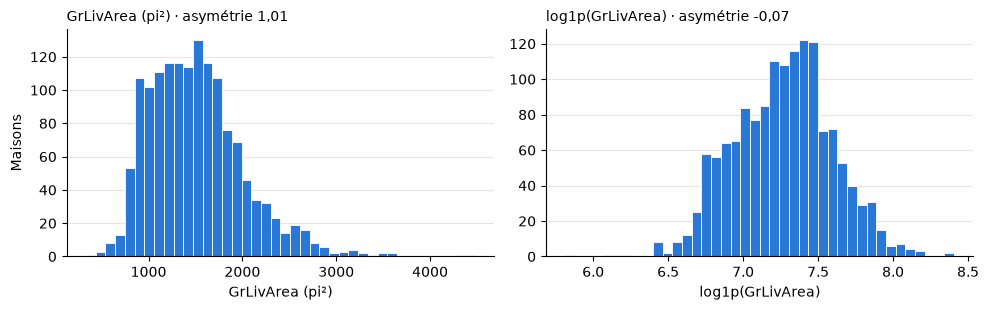

**6.2 Masse de zéros : 2ndFlrSF et PoolArea**

,2ndFlrSF (pi²),log1p,Écart brut,Écart après log1p
Id,,,,
2,0,0.00,NaN,NaN
185,316,5.76,316.0,5.76
12,1142,7.04,826.0,1.28


2ndFlrSF : 57% de zéros. PoolArea : 99.6% de zéros, asymétrie 15.9 → 15.5 après log1p.


**6.2 Rapport de SkewCorrector**

10 colonnes passent au log : LotFrontage, LotArea, BsmtFinSF1, BsmtUnfSF, 1stFlrSF, GrLivArea, OpenPorchSF, TotalSF, TotalPorchSF, QualxArea


,Asymétrie,Part de zéros,Décision,Raison,Asymétrie après
Colonne,,,,,
PoolQC,17.55,1.00,inchangée,"Année, mois, score, comptage ou échelle ordinale",17.55
KitchenAbvGr,4.48,0.00,inchangée,"Année, mois, score, comptage ou échelle ordinale",4.48
BsmtFinType2,3.30,0.03,inchangée,"Année, mois, score, comptage ou échelle ordinale",3.30
ExterCond,1.40,0.00,inchangée,"Année, mois, score, comptage ou échelle ordinale",1.40
BsmtExposure,1.11,0.03,inchangée,"Année, mois, score, comptage ou échelle ordinale",1.11
ExterQual,0.82,0.00,inchangée,"Année, mois, score, comptage ou échelle ordinale",0.82
OverallCond,0.69,0.00,inchangée,"Année, mois, score, comptage ou échelle ordinale",0.69
KitchenQual,0.38,0.00,inchangée,"Année, mois, score, comptage ou échelle ordinale",0.38
MoSold,0.22,0.00,inchangée,"Année, mois, score, comptage ou échelle ordinale",0.22


... (19 outputs left out)

Toutes les vérifications passent : 64 colonnes numériques standardisées.


,Moyenne dans train,Moyenne dans test
LotArea,-0.0,-0.058
GrLivArea,-0.0,-0.037
OverallQual,-0.0,-0.011
TotalSF,-0.0,-0.042
KitchenQual,-0.0,0.001


**6.8 Récapitulatif**

,Colonnes concernées,Paramètre appris sur train,Justification
Opération,,,
log1p,10 colonnes à longue queue,Liste des colonnes,Rend symétriques les grandeurs étirées vers la...
Standardisation,64 colonnes numériques,Moyenne et écart type,Pénalité de Ridge équitable; même poids pour l...
Aucune,163 colonnes one-hot,—,Déjà sur une échelle 0/1 commune


In [13]:
# ──────────────────────────────────────────────────────────────────────
# 6.1 Trois notions à ne pas confondre
# ──────────────────────────────────────────────────────────────────────
show_title("6.1 Trois notions à ne pas confondre")
# Le pipeline s'ajuste sur l'entraînement sans les deux ventes aberrantes : nous faisons de même.
fit_rows, fit_prices = remove_outliers(ordered, y)
fit_ids = X.loc[fit_rows.index, "Id"]
lot = fit_rows["LotArea"]
positions = lot.sort_values().index[[0, len(lot) // 4, len(lot) // 2, 3 * len(lot) // 4, -1]]
display(pd.DataFrame({
    "Id": fit_ids.loc[positions],
    "Brute (pi²)": lot.loc[positions],
    "log1p": np.log1p(lot.loc[positions]),
    "Min-max": (lot.loc[positions] - lot.min()) / (lot.max() - lot.min()),
    "Standardisée": (lot.loc[positions] - lot.mean()) / lot.std(ddof=0),
}).set_index("Id").round(2))


# ──────────────────────────────────────────────────────────────────────
# 6.2 Longue queue : GrLivArea
# ──────────────────────────────────────────────────────────────────────
show_title("6.2 Longue queue : GrLivArea")
skew = SkewCorrector().fit(fit_rows)
living = fit_rows["GrLivArea"]
display(pd.DataFrame({
    "10e centile": [living.quantile(0.1), np.log1p(living.quantile(0.1))],
    "90e centile": [living.quantile(0.9), np.log1p(living.quantile(0.9))],
    "Asymétrie": [living.skew(), np.log1p(living).skew()],
}, index=["Brute (pi²)", "log1p"]).round(2))

figure, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for axis, values, label in [(axes[0], living, "GrLivArea (pi²)"), (axes[1], np.log1p(living), "log1p(GrLivArea)")]:
    axis.hist(values, bins=40, color="#2a78d6", edgecolor="white", linewidth=0.6)
    axis.set_title(f"{label} · asymétrie {values.skew():.2f}".replace(".", ","), fontsize=10, loc="left")
    axis.set_xlabel(label)
    axis.grid(axis="y", color="#e6e5e1", linewidth=0.8)
    axis.set_axisbelow(True)
    axis.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Maisons")
plt.tight_layout()
plt.show()


# ──────────────────────────────────────────────────────────────────────
# 6.2 Masse de zéros : 2ndFlrSF et PoolArea
# ──────────────────────────────────────────────────────────────────────
show_title("6.2 Masse de zéros : 2ndFlrSF et PoolArea")
second = ordered.set_axis(X["Id"]).loc[[2, 185, 12], "2ndFlrSF"]
floors = pd.DataFrame({"2ndFlrSF (pi²)": second, "log1p": np.log1p(second)})
floors["Écart brut"] = floors["2ndFlrSF (pi²)"].diff()
floors["Écart après log1p"] = floors["log1p"].diff()
display(floors.round(2))
pool = fit_rows["PoolArea"]
print(f"2ndFlrSF : {fit_rows['2ndFlrSF'].eq(0).mean():.0%} de zéros. "
      f"PoolArea : {pool.eq(0).mean():.1%} de zéros, asymétrie {pool.skew():.1f} → "
      f"{np.log1p(pool).skew():.1f} après log1p.")


# ──────────────────────────────────────────────────────────────────────
# 6.2 Rapport de SkewCorrector
# ──────────────────────────────────────────────────────────────────────
show_title("6.2 Rapport de SkewCorrector")
report = skew.skew_report_.set_index("Colonne")
corrected = skew.transform(fit_rows)
report["Asymétrie après"] = [corrected[column].skew() for column in report.index]
report = report.sort_values(["Décision", "Raison", "Asymétrie"], ascending=[True, True, False])
print(f"{len(skew.log_columns_)} colonnes passent au log : {', '.join(skew.log_columns_)}")
with pd.option_context("display.max_rows", None):
    display(report.round(2))


# ──────────────────────────────────────────────────────────────────────
# 6.3 Asymétrie avec et sans les deux ventes aberrantes
# ──────────────────────────────────────────────────────────────────────
show_title("6.3 Asymétrie avec et sans les deux ventes aberrantes")
borderline = ["TotalBsmtSF", "BsmtFinSF1", "TotalSF"]
display(pd.DataFrame({"Avec les 2 ventes": ordered[borderline].skew(),
                      "Sans (pipeline)": fit_rows[borderline].skew()}).round(2))


# ──────────────────────────────────────────────────────────────────────
# 6.3 Règles de log, trois découpages
# ──────────────────────────────────────────────────────────────────────
show_title("6.3 Règles de log, trois découpages")
seeds = [42, 1, 7]

def repeated_cv(build):
    """RMSE log hors pli pour cinq plis, répétée avec trois découpages différents."""
    scores = []
    for seed in seeds:
        predictions = pd.Series(np.nan, index=y.index)
        for fit_index, valid_index in KFold(n_splits=5, shuffle=True, random_state=seed).split(X):
            fit_features, prices = remove_outliers(X.iloc[fit_index], y.iloc[fit_index])
            model = build().fit(fit_features, np.log(prices))
            predictions.iloc[valid_index] = np.exp(model.predict(X.iloc[valid_index]))
        scores.append(cv_rmse(y, predictions, X))
    return scores

def scaling_model(kind="standard", **skew_options):
    """Prétraitement des sections 2 à 5, puis log, mise à l’échelle et RidgeCV."""
    columns = ColumnTransformer([
        ("numeric", make_scaler(kind), make_column_selector(dtype_include="number")),
        ("nominal", make_onehot_encoder(), nominal_columns),
    ])
    return make_pipeline(Cleaner(), MissingValueHandler(), FeatureCreator(), QualityOrdinalEncoder(),
                         SkewCorrector(**skew_options), columns, RidgeCV(alphas=np.logspace(-1, 3, 30)))

def score_table(results):
    """Une ligne par option : score de chaque découpage, puis moyenne ± écart type."""
    table = pd.DataFrame(results, index=[f"random_state={seed}" for seed in seeds]).T
    table["Moyenne ± écart type"] = [f"{np.mean(s):.4f} ± {np.std(s):.4f}" for s in results.values()]
    return table.round(4)

rules = {
    "Aucun log": {"threshold": None},
    "Seuil 0,75": {"threshold": 0.75, "max_zero_share": 1.0},
    "Seuil 0,5": {"threshold": 0.5, "max_zero_share": 1.0},
    "Seuil 0,75 sans colonnes surtout nulles (choix)": {},
    "Seuil 0,5 sans colonnes surtout nulles": {"threshold": 0.5},
}
display(score_table({name: repeated_cv(lambda: scaling_model(**options)) for name, options in rules.items()}))


# ──────────────────────────────────────────────────────────────────────
# 6.4 Variances brutes
# ──────────────────────────────────────────────────────────────────────
show_title("6.4 Variances brutes")
display(fit_rows[["LotArea", "GrLivArea", "OverallQual"]].var().rename("Variance").to_frame().round(1))


# ──────────────────────────────────────────────────────────────────────
# 6.4 Ridge et unités
# ──────────────────────────────────────────────────────────────────────
show_title("6.4 Ridge et unités")
def unit_score(acres, scaled):
    """RMSE log d’un petit modèle Ridge selon l’unité de LotArea et la mise à l’échelle."""
    data = fit_rows[["LotArea", "GrLivArea", "OverallQual"]].copy()
    if acres:
        data["LotArea"] = data["LotArea"] / 43_560  # 1 acre = 43 560 pi²
    model = make_pipeline(StandardScaler(), Ridge(alpha=100)) if scaled else Ridge(alpha=100)
    predictions = cross_val_predict(model, data, np.log(fit_prices), cv=folds)
    return rmse_log(fit_prices, np.exp(predictions))

display(pd.DataFrame({unit: [unit_score(unit == "acres", scaled) for scaled in (False, True)]
                      for unit in ("pi²", "acres")},
                     index=["Sans mise à l’échelle", "Standardisé"]).round(4))


# ──────────────────────────────────────────────────────────────────────
# 6.4 ACP brute ou standardisée
# ──────────────────────────────────────────────────────────────────────
show_title("6.4 ACP brute ou standardisée")
numeric_fit = fit_rows.select_dtypes(include="number")
rows = []
for name, data in [("Brutes", numeric_fit), ("Standardisées", StandardScaler().fit_transform(numeric_fit))]:
    component = PCA(n_components=1).fit(data)
    weights = pd.Series(component.components_[0], index=numeric_fit.columns).abs()
    rows.append([name, component.explained_variance_ratio_[0], weights["LotArea"],
                 ", ".join(weights.nlargest(3).index)])
display(pd.DataFrame(rows, columns=["Données", "Variance expliquée par la 1re composante",
                                    "Poids de LotArea", "3 plus gros poids"]).set_index("Données").round(3))
standardized = StandardScaler().fit_transform(numeric_fit)
same = np.allclose(np.cov(standardized, rowvar=False, ddof=0), numeric_fit.corr().to_numpy())
print(f"Covariance des données standardisées = matrice des corrélations : {same}")


# ──────────────────────────────────────────────────────────────────────
# 6.5 Aucune mise à l’échelle, min-max ou standardisation
# ──────────────────────────────────────────────────────────────────────
show_title("6.5 Aucune mise à l’échelle, min-max ou standardisation")
scalers = {"Aucune mise à l’échelle": "none", "Min-max": "minmax", "Standardisation (choix)": "standard"}
display(score_table({name: repeated_cv(lambda: scaling_model(kind)) for name, kind in scalers.items()}))


# ──────────────────────────────────────────────────────────────────────
# 6.5 Min-max de LotArea avant et après log1p
# ──────────────────────────────────────────────────────────────────────
show_title("6.5 Min-max de LotArea avant et après log1p")
def min_max(values):
    return (values - values.min()) / (values.max() - values.min())

display(pd.DataFrame({
    "Maison médiane": [min_max(lot).median(), min_max(np.log1p(lot)).median()],
    "Part entre 0 et 0,1": [min_max(lot).lt(0.1).mean(), min_max(np.log1p(lot)).lt(0.1).mean()],
}, index=["Min-max des valeurs brutes", "Min-max après log1p"]).round(3))
print(f"Plus grand terrain : {lot.max():,.0f} pi²".replace(",", " "))


# ──────────────────────────────────────────────────────────────────────
# 6.6 Ce qui est mis à l’échelle
# ──────────────────────────────────────────────────────────────────────
show_title("6.6 Ce qui est mis à l’échelle")
numeric_columns = fit_rows.select_dtypes(include="number").columns
binary = [column for column in numeric_columns if fit_rows[column].nunique() <= 2]
display(pd.DataFrame([
    ["Numériques continues ou comptages", len(numeric_columns) - len(ORDINAL_COLUMNS) - len(binary), "Oui"],
    ["Ordinales (section 5)", len(ORDINAL_COLUMNS), "Oui"],
    ["Indicateurs 0/1", len(binary), "Oui"],
    ["One-hot (section 5)", onehot_columns, "Non, restent 0/1"],
], columns=["Colonnes", "Nombre", "Standardisées"]).set_index("Colonnes"))


# ──────────────────────────────────────────────────────────────────────
# 6.7 Vérifications
# ──────────────────────────────────────────────────────────────────────
show_title("6.7 Vérifications")
scaler = make_scaler().set_output(transform="pandas")
scaled_train = scaler.fit_transform(skew.transform(fit_rows)[numeric_columns])
scaled_test = scaler.transform(skew.transform(ordered_test)[numeric_columns])
assert np.allclose(scaled_train.mean(), 0) and np.allclose(scaled_train.std(ddof=0), 1)
for frame in (scaled_train, scaled_test):
    assert np.isfinite(frame.to_numpy()).all()
assert not set(skew.log_columns_) & set(NO_LOG_COLUMNS)
assert all(fit_rows[column].nunique() > 2 for column in skew.log_columns_)
print(f"Toutes les vérifications passent : {len(numeric_columns)} colonnes numériques standardisées.")
display(pd.DataFrame({"Moyenne dans train": scaled_train.mean(), "Moyenne dans test": scaled_test.mean()})
        .loc[["LotArea", "GrLivArea", "OverallQual", "TotalSF", "KitchenQual"]].round(3))


# ──────────────────────────────────────────────────────────────────────
# 6.8 Récapitulatif
# ──────────────────────────────────────────────────────────────────────
show_title("6.8 Récapitulatif")
display(pd.DataFrame([
    ["log1p", f"{len(skew.log_columns_)} colonnes à longue queue", "Liste des colonnes",
     "Rend symétriques les grandeurs étirées vers la droite"],
    ["Standardisation", f"{len(numeric_columns)} colonnes numériques", "Moyenne et écart type",
     "Pénalité de Ridge équitable; même poids pour l’ACP"],
    ["Aucune", f"{onehot_columns} colonnes one-hot", "—", "Déjà sur une échelle 0/1 commune"],
], columns=["Opération", "Colonnes concernées", "Paramètre appris sur train", "Justification"])
        .set_index("Opération"))

## 7. Sélection des variables (stratégies)

Après la section 6, chaque maison est décrite par 227 colonnes. Plusieurs mesurent la même chose : une somme et ses parties (section 4), une année et un âge, un équipement et son indicateur `Has…`. Ridge tolère cette redondance, car sa pénalité partage l’effet entre des colonnes semblables. Réduire le nombre de colonnes peut quand même aider : un modèle plus petit se lit mieux, et une régression sans pénalité supporte mal des colonnes presque identiques.

Nous comparons quatre stratégies à la base sans sélection.

| Recette | Idée | Appris sur l’entraînement |
|---|---|---|
| Base | Garder les 227 colonnes | — |
| Corrélation | Garder les colonnes liées au prix, puis retirer les doublons statistiques | Corrélations de Spearman |
| Causale | Retirer ce qui mesure une deuxième fois une même cause du prix | Rien : règles fixées à l’avance |
| ACP | Remplacer les colonnes numériques par leurs premières composantes | Axes de l’ACP |
| Causale + ACP par blocs | Sélection causale, puis une composante par équipement | Axes de chaque bloc |

**Protocole.** Les cinq recettes viennent de `src/preprocessing/pipelines.py` (section 8). Chacune est suivie de RidgeCV et évaluée comme à la section 6.3 : validation croisée à cinq plis répétée avec trois découpages, retrait ciblé dans l’entraînement de chaque pli et RMSE log sur les ventes typiques. La sélection est apprise dans chaque pli, jamais sur les maisons de validation.

**Prudence.** Les seuils des sections 7.1 et 7.3 sont choisis avec ces mêmes plis. Le score de la recette retenue est donc un peu optimiste, d’autant que les écarts entre seuils voisins sont petits.

### 7.1 Sélection par corrélation

`CorrelationSelector` applique deux filtres, appris dans chaque pli :

1. **Pertinence** : une colonne est gardée si la valeur absolue de son Spearman avec le prix atteint un premier seuil.
2. **Redondance** : les colonnes sont parcourues de la plus liée au prix à la moins liée. Une colonne est retirée si son Spearman avec une colonne déjà gardée atteint un second seuil.

La sélection s’applique après l’encodage. Elle juge chaque colonne one-hot séparément et chaque échelle ordinale en entier (section 5.4). La sortie « 7.1 Seuils de la sélection par corrélation » croise quatre seuils de pertinence et trois de redondance.

**Lecture.**
- **La pertinence n’admet qu’un seuil bas.** Jusqu’à 0,05, l’erreur ne monte pas. À 0,1, elle monte légèrement (0,1120 sans filtre de redondance); à 0,2, elle bondit à 0,1256. On retire alors des colonnes faibles prises seules mais utiles ensemble, comme plusieurs quartiers.
- **Le seuil de redondance de 0,8 retenu à l’étape 3 retire trop.** Il coûte environ 0,002, quel que soit le seuil de pertinence. La sortie « 7.1 Colonnes retirées par la recette retenue » montre pourquoi : à 0,8, `QualxArea` élimine `OverallQual` et `TotalSF`, et `TotalBsmtSF` élimine `1stFlrSF`. Ces colonnes sont proches, mais ce ne sont pas des doublons. À 0,9, la sélection retire surtout de vrais doublons : `AgeAtSale` et `YearBuilt`, `HasPool` et `PoolQC`, `CentralAir_Y` et `CentralAir_N`.

**Décision.** Pertinence 0,05 et redondance 0,9 : 154 colonnes sur 227, pour 0,1107 ± 0,0009 contre 0,1112 ± 0,0008 sans sélection. Les 73 colonnes retirées comprennent 48 colonnes sans lien avec le prix et 25 doublons.

**Limite.** Entre deux doublons, la sélection garde celui qui a le plus grand Spearman, sans tenir compte du sens. `GrLivArea` disparaît au profit de `QualxArea`, et `AgeAtSale` au profit de `YearBuilt`. Le modèle reste aussi bon, mais un coefficient de `QualxArea` se commente moins facilement qu’une surface.

### 7.2 Sélection causale

La sélection par corrélation choisit d’après les données. `CausalSelector` choisit d’après un raisonnement fixé à l’avance. Le prix dépend de quelques causes : taille, qualité, âge, emplacement, équipements et conditions de la vente. Chacune doit être mesurée une seule fois. Trois règles retirent les colonnes qui mesurent une cause déjà présente (sortie « 7.2 Règles de la sélection causale ») :

1. **Doublon.** `YearBuilt` répète `AgeAtSale`, et `YearRemodAdd` répète `YearsSinceRemodel`. `GarageYrBlt` égale `YearBuilt` pour 79 % des garages (section 3.2) et pour toutes les maisons sans garage.
2. **Conséquence.** La surface habitable détermine le nombre de pièces (`TotRmsAbvGrd`), et la surface du garage détermine le nombre de places (`GarageCars`). Garder les deux partagerait l’effet de la cause avec une mesure plus grossière.
3. **Surface comptée une fois.** Une somme n’est jamais gardée avec toutes ses parties. Cette règle tranche la question laissée ouverte à la section 4.3.

Aucune colonne n’est retirée parce que son lien avec le prix est faible : une piscine influence le prix, même si elle est rare. Les causes communes restent aussi ensemble. L’étape 3 notait que l’effet apparent de l’âge peut refléter la taille et la qualité. Garder ces trois causes évite que le coefficient de l’âge absorbe les deux autres.

**Sommes ou parties** (sortie « 7.2 Sommes ou parties »). Garder les sommes coûte 0,0015 (0,1127 contre 0,1112). Garder les parties ne coûte que 0,0005 (0,1117). C’est la conclusion de la section 4.3 : un pi² de sous-sol, de rez-de-chaussée et d’étage n’a pas la même valeur, mais `TotalSF` leur donne le même poids.

**Décision.** Mode « parties » (`CAUSAL_MODE`) : 10 colonnes retirées, 217 restantes. La sélection causale ne réduit pas l’erreur. Son intérêt est ailleurs : chaque cause garde une seule colonne, ce qui rend les coefficients lisibles.

### 7.3 Analyse en composantes principales

`PCAReducer` remplace les 64 colonnes numériques standardisées par leurs premières composantes principales. Les 163 colonnes one-hot restent telles quelles, car l’ACP se prête mal aux colonnes 0/1 presque vides (section 5.4). La standardisation préalable est indispensable (section 6.4).

**Lecture** (sortie « 7.3 Variance expliquée par l’ACP »). La variance est très étalée : il faut 21 composantes pour 80 % de la variance, 37 pour 95 % et 49 pour 99 %. Aucun petit nombre d’axes ne résume les maisons. Les colonnes numériques décrivent des aspects en partie indépendants : surfaces, qualités et équipements rares.

La sortie « 7.3 Part de variance conservée » montre que l’erreur baisse tant qu’on conserve de la variance : 0,1206 à 80 %, 0,1123 à 95 %, puis 0,1115 à 99 % comme à 99,9 %. L’ACP classe les axes par variance, sans regarder le prix. Les dernières composantes ont peu de variance, mais certaines portent de l’information sur le prix.

**Décision.** 99 % de la variance (`PCA_VARIANCE`) : 49 composantes au lieu de 64 colonnes, pour 0,1115 ± 0,0011, presque le score de la base. Le gain de place est modeste, et les composantes ne se lisent plus comme des caractéristiques de la maison.

### 7.4 Sélection causale et ACP par blocs

L’ACP globale mélange toutes les colonnes. `BlockPCA` applique l’ACP séparément à de petits blocs de colonnes qui décrivent un même équipement, après la sélection causale. Chaque bloc devient une seule composante, qui garde un sens, par exemple « présence, nombre et qualité des foyers ».

Un bloc réunit des colonnes d’un même équipement dont le Spearman reste d’au moins 0,8 après la sélection causale. On obtient huit blocs : la piscine, l’autre équipement (`MiscVal`), le foyer, le parement de maçonnerie, l’étage, les deux parties finies du sous-sol et l’état du garage (`GarageQual`, `GarageCond`). Deux paires aussi corrélées restent séparées : `OverallQual` et `QualxArea`, car l’interaction perdrait son rôle, et `TotalBsmtSF` et `1stFlrSF`, deux niveaux dont le pi² n’a pas la même valeur (section 4.3).

**Lecture** (sortie « 7.4 Blocs de l’ACP par blocs »). Dans chaque bloc, la première composante explique de 73 % (`MiscVal`) à 98 % (état du garage) de la variance. Les poids sont presque égaux : la composante revient à une moyenne des colonnes standardisées du bloc. Les 18 colonnes des blocs deviennent 8 composantes, pour un total de 207 colonnes. Le score figure à la section 7.5.

### 7.5 Comparaison des cinq recettes

La sortie « 7.5 Comparaison des cinq recettes » réunit les recettes retenues aux sections 7.1 à 7.4.

| Recette | Colonnes | RMSE log | Écart avec la base |
|---|---|---|---|
| Base | 227 | 0,1112 ± 0,0008 | — |
| **Corrélation** | **154** | **0,1107 ± 0,0009** | **−0,0005** |
| Causale | 217 | 0,1117 ± 0,0007 | +0,0005 |
| ACP | 212 | 0,1115 ± 0,0011 | +0,0003 |
| Causale + ACP par blocs | 207 | 0,1123 ± 0,0008 | +0,0011 |

**Lecture.** Les cinq recettes se tiennent dans 0,0016, à peine deux écarts types entre découpages. Aucune stratégie ne change nettement l’erreur : la pénalité de Ridge gère déjà la redondance. La sélection par corrélation est la seule meilleure que la base en moyenne, avec un tiers de colonnes en moins. Elle ne l’est pas avec les trois découpages (0,1104 contre 0,1102 avec `random_state=7`), et ses seuils ont été choisis sur ces mêmes plis. L’ACP par blocs est la moins bonne : une composante impose un même coefficient aux colonnes de son bloc, alors que Ridge pouvait pondérer séparément, par exemple, un indicateur et sa mesure.

### 7.6 Décision

**Recette de référence pour l’étape 5 : la base** (`make_base()`). Aucune stratégie ne fait nettement mieux qu’elle, et elle ne perd aucune information.

Les quatre stratégies restent disponibles dans `src/preprocessing/pipelines.py` :
- **Corrélation** (`make_correlation()`) : la candidate à tester à l’étape 5, car elle fait au moins aussi bien avec 154 colonnes. Son avantage devra être confirmé avec le modèle final, sur des plis qui n’ont pas servi à choisir ses seuils.
- **Causale** (`make_causal()`) : pour un modèle à interpréter ou un modèle sans pénalité, sensible aux colonnes redondantes.
- **ACP** et **causale + ACP par blocs** : sans intérêt ici pour Ridge.

Pour des modèles à base d’arbres, comme XGBoost, la sélection compte peu : un arbre choisit lui-même ses colonnes, et le log et la standardisation ne changent pas ses découpes.

**7.1 Seuils de la sélection par corrélation**

,Colonnes,random_state=42,random_state=1,random_state=7,Moyenne ± écart type
"Lien ≥ 0 · redondance 0,8",179,0.1142,0.1129,0.1121,0.1131 ± 0.0008
"Lien ≥ 0 · redondance 0,9",198,0.1120,0.1106,0.1100,0.1108 ± 0.0008
Lien ≥ 0 · redondance aucun filtre,227,0.1123,0.1112,0.1102,0.1112 ± 0.0008
"Lien ≥ 0,05 · redondance 0,8",136,0.1142,0.1122,0.1125,0.1130 ± 0.0009
"Lien ≥ 0,05 · redondance 0,9",154,0.1120,0.1098,0.1104,0.1107 ± 0.0009
"Lien ≥ 0,05 · redondance aucun filtre",179,0.1122,0.1104,0.1104,0.1110 ± 0.0009
"Lien ≥ 0,1 · redondance 0,8",103,0.1153,0.1135,0.1126,0.1138 ± 0.0011
"Lien ≥ 0,1 · redondance 0,9",119,0.1134,0.1114,0.1114,0.1121 ± 0.0009
"Lien ≥ 0,1 · redondance aucun filtre",137,0.1134,0.1117,0.1111,0.1120 ± 0.0010
"Lien ≥ 0,2 · redondance 0,8",57,0.1280,0.1298,0.1277,0.1285 ± 0.0009


**7.1 Colonnes retirées par la recette retenue**

Raison
Liée au prix, non redondante    154
Lien faible avec le prix         48
Redondante                       25


,|Spearman| avec le prix,Colonne gardée à sa place
Colonne,,
GrLivArea,0.732,QualxArea
AgeAtSale,0.651,YearBuilt
YearRemodAdd,0.572,YearsSinceRemodel
HasFireplace,0.526,FireplaceQu
MasVnrType_None,0.390,MasVnrArea
HasMasonryVeneer,0.390,MasVnrArea
Exterior1st_VinylSd,0.373,Exterior2nd_VinylSd
CentralAir_Y,0.313,CentralAir_N
SaleCondition_Partial,0.305,SaleType_New


Lien faible, exemples : SaleCondition_Family, Exterior2nd_Stucco, Exterior2nd_infrequent_sklearn, MSSubClass_85, Neighborhood_Mitchel, Street_infrequent_sklearn, Street_Pave, Neighborhood_infrequent_sklearn, BsmtFinType2, Exterior1st_Stucco, LandSlope_Mod, BsmtFinSF2
Retirées en plus avec le seuil 0,8 : TotalSF (gardée : QualxArea), OverallQual (gardée : QualxArea), GarageArea (gardée : GarageCars), GarageYrBlt (gardée : YearBuilt), 1stFlrSF (gardée : TotalBsmtSF), Fireplaces (gardée : FireplaceQu), GarageCond (gardée : GarageQual), SaleType_New (gardée : IsNewHouse), MSZoning_RL (gardée : MSZoning_RM), HouseStyle_2Story (gardée : 2ndFlrSF), PavedDrive_N (gardée : PavedDrive_Y), Electrical_FuseA (gardée : Electrical_SBrkr), Exterior2nd_Wd Sdng (gardée : Exterior1st_Wd Sdng), Foundation_Slab (gardée : HasBasement), MSZoning_FV (gardée : Neighborhood_Somerst), Exterior2nd_AsbShng (gardée : Exterior1st_AsbShng), HouseStyle_1Story (gardée : 2ndFlrSF), Exterior2nd_HdBoard (gardée : Exterior

**7.2 Règles de la sélection causale**

Raison
Mode                       Règle                        Colonne retirée                                                                                          
Garder les sommes          1 · Doublon                  YearBuilt                                          Doublon de AgeAtSale (même information, au signe près)
                                                        YearRemodAdd                               Doublon de YearsSinceRemodel (même information, au signe près)
                                                        GarageYrBlt      Doublon de l’âge : égale YearBuilt pour 79 % des garages et pour les maisons sans garage
                           2 · Conséquence              TotRmsAbvGrd                Conséquence de GrLivArea : la surface habitable détermine le nombre de pièces
                                                        GarageCars                 Conséquence de GarageArea : la surface du garage détermine le nombre de places
                           3 · Surface comptée une fois 1stFlrSF                                                                Partie de TotalSF ou de GrLivArea
                                                        2ndFlrSF                                                                Partie de TotalSF ou de GrLivArea
                                                        TotalBsmtSF                                                Égale TotalSF − GrLivArea, à LowQualFinSF près
                                                        BsmtUnfSF                               Reste du sous-sol : TotalSF − GrLivArea − BsmtFinSF1 − BsmtFinSF2
                                                        FullBath                                                                              Partie de TotalBath
                                                        HalfBath                                                                              Partie de TotalBath
                                                        BsmtFullBath                                                                          Partie de TotalBath
                                                        BsmtHalfBath                                                                          Partie de TotalBath
                                                        WoodDeckSF                                                                         Partie de TotalPorchSF
                                                        OpenPorchSF                                                                        Partie de TotalPorchSF
                                                        EnclosedPorch                                                                      Partie de TotalPorchSF
                                                        3SsnPorch                                                                          Partie de TotalPorchSF
                                                        ScreenPorch                                                                        Partie de TotalPorchSF
Garder les parties (choix) 1 · Doublon                  YearBuilt                                          Doublon de AgeAtSale (même information, au signe près)
                                                        YearRemodAdd                               Doublon de YearsSinceRemodel (même information, au signe près)
                                                        GarageYrBlt      Doublon de l’âge : égale YearBuilt pour 79 % des garages et pour les maisons sans garage
                           2 · Conséquence              TotRmsAbvGrd                Conséquence de GrLivArea : la surface habitable détermine le nombre de pièces
                                                        GarageCars                 Conséquence de GarageArea : la surface du garage détermine le nombre de places
                           3 · Surface comptée une fois TotalSF                                          

**7.2 Sommes ou parties**

,Colonnes,random_state=42,random_state=1,random_state=7,Moyenne ± écart type
Sans sélection,227,0.1123,0.1112,0.1102,0.1112 ± 0.0008
Causale · sommes,209,0.1142,0.1120,0.1119,0.1127 ± 0.0011
Causale · parties (choix),217,0.1126,0.1115,0.1110,0.1117 ± 0.0007


**7.3 Variance expliquée par l’ACP**

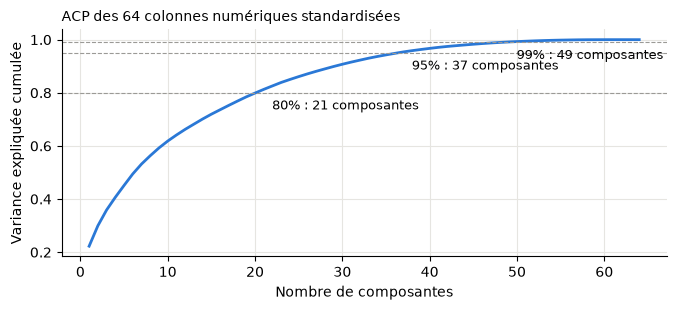

**7.3 Part de variance conservée**

,Colonnes,Composantes,random_state=42,random_state=1,random_state=7,Moyenne ± écart type
"80,0% de la variance",184,21,0.1223,0.1201,0.1194,0.1206 ± 0.0012
"90,0% de la variance",193,30,0.1180,0.1150,0.1146,0.1159 ± 0.0015
"95,0% de la variance",200,37,0.1139,0.1114,0.1117,0.1123 ± 0.0011
"99,0% de la variance",212,49,0.1130,0.1107,0.1107,0.1115 ± 0.0011
"99,9% de la variance",220,57,0.1125,0.1113,0.1106,0.1115 ± 0.0008


**7.4 Blocs de l’ACP par blocs**

Poids
Bloc        Variance expliquée Colonne                
Pool        0.971090           PoolArea          0.579
                               PoolQC            0.570
                               HasPool           0.582
Misc        0.728139           MiscVal           0.707
                               HasMiscFeature    0.707
Fireplace   0.938344           Fireplaces        0.567
                               FireplaceQu       0.578
                               HasFireplace      0.586
Masonry     0.847566           MasVnrArea        0.707
                               HasMasonryVeneer  0.707
SecondFloor 0.955970           2ndFlrSF          0.707
                               Has2ndFloor       0.707
BsmtFin1    0.926214           BsmtFinType1      0.707
                               BsmtFinSF1        0.707
BsmtFin2    0.895766           BsmtFinType2      0.707
                               BsmtFinSF2        0.707
GarageState 0.979584           GarageQual        0.707
                               GarageCond        0.707

**7.5 Comparaison des cinq recettes**

,Colonnes,Écart avec la base,random_state=42,random_state=1,random_state=7,Moyenne ± écart type
Base,227,0.0000,0.1123,0.1112,0.1102,0.1112 ± 0.0008
Corrélation,154,-0.0005,0.1120,0.1098,0.1104,0.1107 ± 0.0009
Causale,217,0.0005,0.1126,0.1115,0.1110,0.1117 ± 0.0007
ACP,212,0.0003,0.1130,0.1107,0.1107,0.1115 ± 0.0011
Causale + ACP par blocs,207,0.0011,0.1135,0.1117,0.1118,0.1123 ± 0.0008


In [14]:
# ──────────────────────────────────────────────────────────────────────
# 7 · Protocole commun
# ──────────────────────────────────────────────────────────────────────
# Mêmes plis et même modèle qu'à la section 6.3 : RidgeCV après la recette testée.
# Les recettes viennent de src/preprocessing/pipelines.py.
raw_fit, raw_prices = remove_outliers(X, y)
memo = {}

def recipe_scores(make, **options):
    """RMSE log (ventes typiques) des trois découpages pour une recette suivie de RidgeCV."""
    key = (make.__name__, tuple(sorted(options.items())))
    if key not in memo:
        memo[key] = repeated_cv(lambda: make_pipeline(make(**options), RidgeCV(alphas=np.logspace(-1, 3, 30))))
    return memo[key]

def fitted_recipe(make, **options):
    """Recette ajustée sur train sans les deux ventes aberrantes, pour décrire ses colonnes."""
    return make(**options).fit(raw_fit, np.log(raw_prices))

def recipe_table(variants):
    """Colonnes produites, score de chaque découpage, puis moyenne ± écart type."""
    table = score_table({name: recipe_scores(make, **options) for name, (make, options) in variants.items()})
    widths = [fitted_recipe(make, **options).transform(raw_fit).shape[1] for make, options in variants.values()]
    table.insert(0, "Colonnes", widths)
    return table


# ──────────────────────────────────────────────────────────────────────
# 7.1 Seuils de la sélection par corrélation
# ──────────────────────────────────────────────────────────────────────
show_title("7.1 Seuils de la sélection par corrélation")
def threshold_label(min_target, max_pair):
    redundancy = "aucun filtre" if max_pair is None else f"{max_pair}".replace(".", ",")
    return f"Lien ≥ {min_target}".replace(".", ",") + f" · redondance {redundancy}"

correlation_variants = {
    threshold_label(min_target, max_pair): (make_correlation, {"min_target_corr": min_target,
                                                              "max_pair_corr": max_pair})
    for min_target in (0, 0.05, 0.1, 0.2) for max_pair in (0.8, 0.9, None)
}
correlation_table = recipe_table(correlation_variants)
display(correlation_table.style.format(precision=4).highlight_min(subset=["Moyenne ± écart type"], color="#d8ecd2"))


# ──────────────────────────────────────────────────────────────────────
# 7.1 Colonnes retirées par la recette retenue
# ──────────────────────────────────────────────────────────────────────
show_title("7.1 Colonnes retirées par la recette retenue")
correlation_report = fitted_recipe(make_correlation)[-1].report_
print(correlation_report["Raison"].value_counts().to_string())
removed_twins = correlation_report[correlation_report["Raison"].eq("Redondante")]
display(removed_twins.drop(columns=["Décision", "Raison"]).set_index("Colonne").round(3))
weak = correlation_report[correlation_report["Raison"].eq("Lien faible avec le prix")]
print("Lien faible, exemples : " + ", ".join(weak["Colonne"].head(12)))
strict = fitted_recipe(make_correlation, max_pair_corr=0.8)[-1].report_
extra = strict[strict["Raison"].eq("Redondante") & ~strict["Colonne"].isin(removed_twins["Colonne"])]
print("Retirées en plus avec le seuil 0,8 : "
      + ", ".join(f"{c} (gardée : {t})" for c, t in zip(extra["Colonne"], extra["Colonne gardée à sa place"])))


# ──────────────────────────────────────────────────────────────────────
# 7.2 Règles de la sélection causale
# ──────────────────────────────────────────────────────────────────────
show_title("7.2 Règles de la sélection causale")
rule_of = {**{c: "1 · Doublon" for c in DUPLICATES}, **{c: "2 · Conséquence" for c in CONSEQUENCES}}
causal_rows = []
for mode, label in [("totals", "Garder les sommes"), ("parts", "Garder les parties (choix)")]:
    for column, reason in causal_drops(mode).items():
        causal_rows.append([label, rule_of.get(column, "3 · Surface comptée une fois"), column, reason])
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(causal_rows, columns=["Mode", "Règle", "Colonne retirée", "Raison"])
            .set_index(["Mode", "Règle", "Colonne retirée"]))


# ──────────────────────────────────────────────────────────────────────
# 7.2 Sommes ou parties
# ──────────────────────────────────────────────────────────────────────
show_title("7.2 Sommes ou parties")
display(recipe_table({"Sans sélection": (make_base, {}),
                      "Causale · sommes": (make_causal, {"mode": "totals"}),
                      "Causale · parties (choix)": (make_causal, {"mode": "parts"})}))


# ──────────────────────────────────────────────────────────────────────
# 7.3 Variance expliquée par l’ACP
# ──────────────────────────────────────────────────────────────────────
show_title("7.3 Variance expliquée par l’ACP")
base_fitted = fitted_recipe(make_base)
numeric_names = base_fitted[-1].named_transformers_["numeric"].get_feature_names_out()
scaled_numeric = base_fitted.transform(raw_fit)[numeric_names]
cumulative = np.cumsum(PCA().fit(scaled_numeric).explained_variance_ratio_)
shares = [0.8, 0.9, 0.95, 0.99, 0.999]
needed = {share: int(np.searchsorted(cumulative, share) + 1) for share in shares}
figure, axis = plt.subplots(figsize=(7, 3.2))
axis.plot(np.arange(1, len(cumulative) + 1), cumulative, color="#2a78d6", linewidth=2)
for share in (0.8, 0.95, 0.99):
    axis.axhline(share, color="#9b9a96", linewidth=0.8, linestyle="--")
    axis.annotate(f"{share:.0%} : {needed[share]} composantes".replace(".", ","),
                  (needed[share], share), xytext=(6, -12), textcoords="offset points", fontsize=9)
axis.set_xlabel("Nombre de composantes")
axis.set_ylabel("Variance expliquée cumulée")
axis.set_title(f"ACP des {len(numeric_names)} colonnes numériques standardisées", fontsize=10, loc="left")
axis.grid(color="#e6e5e1", linewidth=0.8)
axis.set_axisbelow(True)
axis.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


# ──────────────────────────────────────────────────────────────────────
# 7.3 Part de variance conservée
# ──────────────────────────────────────────────────────────────────────
show_title("7.3 Part de variance conservée")
pca_table = recipe_table({f"{share:.1%} de la variance".replace(".", ","): (make_pca, {"n_components": share})
                          for share in shares})
pca_table.insert(1, "Composantes", [needed[share] for share in shares])
display(pca_table)


# ──────────────────────────────────────────────────────────────────────
# 7.4 Blocs de l’ACP par blocs
# ──────────────────────────────────────────────────────────────────────
show_title("7.4 Blocs de l’ACP par blocs")
block_pca = fitted_recipe(make_causal_pca)[-1]
display(block_pca.loadings().set_index(["Bloc", "Variance expliquée", "Colonne"]).round(3))


# ──────────────────────────────────────────────────────────────────────
# 7.5 Comparaison des cinq recettes
# ──────────────────────────────────────────────────────────────────────
show_title("7.5 Comparaison des cinq recettes")
recipes_table = recipe_table({name: (make, {}) for name, make in RECIPES.items()})
recipes_table.insert(1, "Écart avec la base", [np.mean(recipe_scores(make)) - np.mean(recipe_scores(make_base))
                                               for make in RECIPES.values()])
display(recipes_table.round(4))

## 8. Pipelines et reproductibilité

La consigne demande des pipelines scikit-learn, avec des transformations ajustées sur l’entraînement uniquement, y compris dans chaque pli de validation croisée. Les sections 2 à 7 ont choisi chaque étape. `src/preprocessing/pipelines.py` les assemble en cinq recettes.

### 8.1 Les recettes

`make_base()` enchaîne six étapes (sortie « 8.1 Étapes de la recette de base »). Chaque étape a une méthode `fit`, appelée seulement sur les maisons d’entraînement, et une méthode `transform`, appliquée ensuite à n’importe quelles maisons. Trois étapes n’apprennent rien : leurs règles viennent du dictionnaire des variables ou de nos choix. Les trois autres apprennent des statistiques : médianes, colonnes passées au log, moyennes, écarts types et catégories.

Chaque stratégie ajoute des étapes à la base. `CausalSelector` vient après `FeatureCreator`, `PCAReducer` après la standardisation dans la branche numérique, et `CorrelationSelector` et `BlockPCA` à la fin. Chaque recette rend un DataFrame aux colonnes nommées et ne contient pas de modèle : l’étape 5 en ajoute un, par exemple avec `make_pipeline(make_base(), RidgeCV())`.

**Les deux ventes aberrantes.** Leur retrait n’est pas une étape du pipeline. Un transformateur scikit-learn transforme les colonnes, mais ne peut pas retirer des lignes de `y`. `remove_outliers` s’applique donc aux données d’entraînement avant `fit`, jamais à la validation ni à `test.csv`.

### 8.2 Ajustement sur l’entraînement seulement

Nous ajustons chaque recette sur les 80 % d’entraînement de la partition, sans les deux ventes aberrantes (1 166 maisons). Nous transformons ensuite la validation (292 maisons) et `test.csv` (1 459 maisons). La sortie « 8.2 » vérifie trois points pour les cinq recettes :

1. Les trois fichiers reçoivent les mêmes colonnes, dans le même ordre, même si `test.csv` contient des catégories absentes de l’entraînement.
2. Aucune valeur n’est absente ni infinie.
3. Une maison de test reçoit les mêmes valeurs, qu’elle soit transformée seule ou dans un lot. `transform` n’apprend donc rien des maisons qu’il reçoit : aucune statistique de validation ou de test n’entre dans le prétraitement.

Les paramètres appris dépendent seulement des maisons passées à `fit`. La moyenne de `log1p(GrLivArea)` vaut 7,2756 avec 80 % de train, et 7,2668 avec tout train. Dans la validation croisée des sections 2 à 7, la recette est réajustée de zéro dans chaque pli, comme ici.

Avec 80 % de train, la base produit 221 colonnes au lieu de 227. Quelques catégories y comptent moins de 10 maisons et rejoignent la colonne « autre ».

### 8.3 Reproductibilité

Deux ajustements de chaque recette, dont un sur un clone (`sklearn.base.clone`, utilisé par la validation croisée), donnent exactement les mêmes colonnes (sortie « 8.3 »). Aucune étape ne fait de tirage aléatoire. Les seuls tirages sont le découpage 80/20 et les plis, fixés par `random_state`. La sortie donne aussi les versions de Python et des bibliothèques qui ont produit les résultats de ce notebook. Les dépendances sont déclarées dans `pyproject.toml`.

### 8.4 Utilisation à l’étape 5

```python
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline

from src.evaluation import cv_rmse
from src.preprocessing.pipelines import make_base
from src.preprocessing.steps.cleaning import remove_outliers

features, prices = remove_outliers(X_train, y_train)  # entraînement seulement
model = make_pipeline(make_base(), RidgeCV()).fit(features, np.log(prices))
predictions = np.exp(model.predict(X_valid))           # aucune ligne retirée
score = cv_rmse(y_valid, predictions, X_valid)          # RMSE log, ventes typiques
```

Pour une autre recette, il suffit de remplacer `make_base` par `make_correlation`, `make_causal`, `make_pca` ou `make_causal_pca`.

In [15]:
# ──────────────────────────────────────────────────────────────────────
# 8.1 Étapes de la recette de base
# ──────────────────────────────────────────────────────────────────────
show_title("8.1 Étapes de la recette de base")
learned = {
    "cleaner": ("2", "Rien : règles fixes"),
    "missingvaluehandler": ("3", "Médianes, modes et façade médiane par quartier"),
    "featurecreator": ("4", "Rien : formules fixes"),
    "qualityordinalencoder": ("5", "Rien : échelles du dictionnaire"),
    "skewcorrector": ("6", "Colonnes passées au log"),
    "columntransformer": ("5 et 6", "Moyennes et écarts types; catégories et regroupements des rares"),
}
display(pd.DataFrame([[name, type(step).__name__, *learned[name]] for name, step in make_base().steps],
                     columns=["Étape", "Classe", "Section", "Appris dans fit"]).set_index("Étape"))
def step_names(recipe):
    """Classes des étapes, y compris celles de la branche numérique du ColumnTransformer."""
    numeric = recipe.named_steps["columntransformer"].transformers[0][1]
    return [type(step).__name__ for _, step in [*recipe.steps, *numeric.steps]]

print("Étapes ajoutées à la base par chaque stratégie (section 7) :")
for name, make in RECIPES.items():
    extra = [step for step in step_names(make()) if step not in step_names(make_base())]
    print(f"  {name:<25} {', '.join(extra) or '—'}")


# ──────────────────────────────────────────────────────────────────────
# 8.2 Ajustement sur l’entraînement seulement
# ──────────────────────────────────────────────────────────────────────
show_title("8.2 Ajustement sur l’entraînement seulement")
part_X, part_prices = remove_outliers(X.loc[train_index], y.loc[train_index])
holdout_X = X.loc[holdout_index]
rows = []
for name, make in RECIPES.items():
    recipe = make().fit(part_X, np.log(part_prices))
    outputs = {"Entraînement": recipe.transform(part_X), "Validation": recipe.transform(holdout_X),
               "test.csv": recipe.transform(test)}
    for file, frame in outputs.items():
        assert list(frame.columns) == list(outputs["Entraînement"].columns)
        assert np.isfinite(frame.to_numpy(dtype=float)).all()
    # Une maison est transformée de la même façon seule ou avec les autres :
    # transform n'apprend rien des maisons qu'il reçoit.
    halves = pd.concat([recipe.transform(test.iloc[:700]), recipe.transform(test.iloc[700:])])
    alone = recipe.transform(test.iloc[[0]])
    assert np.allclose(halves.to_numpy(dtype=float), outputs["test.csv"].to_numpy(dtype=float))
    assert np.allclose(alone.to_numpy(dtype=float), outputs["test.csv"].iloc[[0]].to_numpy(dtype=float))
    rows.append([name, *(len(frame) for frame in outputs.values()), outputs["Entraînement"].shape[1]])
display(pd.DataFrame(rows, columns=["Recette", "Maisons d’entraînement", "Maisons de validation",
                                    "Maisons de test.csv", "Colonnes"]).set_index("Recette"))
print("Toutes les vérifications passent : mêmes colonnes, aucune valeur absente ou infinie, "
      "même résultat pour une maison seule ou dans un lot.")

# Les paramètres appris dépendent des seules maisons passées à fit.
def learned_mean(features, prices, column="GrLivArea"):
    scaler = make_base().fit(features, np.log(prices))[-1].named_transformers_["numeric"][0]
    return scaler.mean_[list(scaler.feature_names_in_).index(column)]

print(f"Moyenne apprise de log1p(GrLivArea) : {learned_mean(part_X, part_prices):.4f} avec 80 % de train, "
      f"{learned_mean(raw_fit, raw_prices):.4f} avec tout train.")


# ──────────────────────────────────────────────────────────────────────
# 8.3 Reproductibilité
# ──────────────────────────────────────────────────────────────────────
show_title("8.3 Reproductibilité")
import sys
import sklearn
from sklearn.base import clone

for name, make in RECIPES.items():
    first = make().fit(part_X, np.log(part_prices)).transform(holdout_X)
    second = clone(make().fit(part_X, np.log(part_prices))).fit(part_X, np.log(part_prices)).transform(holdout_X)
    assert first.equals(second), name
print("Deux ajustements de chaque recette, dont un sur un clone, donnent exactement les mêmes colonnes.")
display(pd.DataFrame([
    ["Partition 80/20", "train_test_split(random_state=42)"],
    ["Validation croisée", "KFold(5, shuffle=True, random_state=42); 1 et 7 pour les répétitions"],
    ["ACP", "svd_solver=\"full\" : calcul exact, sans tirage aléatoire"],
    ["Python", sys.version.split()[0]],
    ["numpy · pandas · scikit-learn", f"{np.__version__} · {pd.__version__} · {sklearn.__version__}"],
], columns=["Élément", "Valeur"]).set_index("Élément"))

**8.1 Étapes de la recette de base**

,Classe,Section,Appris dans fit
Étape,,,
cleaner,Cleaner,2,Rien : règles fixes
missingvaluehandler,MissingValueHandler,3,"Médianes, modes et façade médiane par quartier"
featurecreator,FeatureCreator,4,Rien : formules fixes
qualityordinalencoder,QualityOrdinalEncoder,5,Rien : échelles du dictionnaire
skewcorrector,SkewCorrector,6,Colonnes passées au log
columntransformer,ColumnTransformer,5 et 6,Moyennes et écarts types; catégories et regrou...


Étapes ajoutées à la base par chaque stratégie (section 7) :
  Base                      —
  Corrélation               CorrelationSelector
  Causale                   CausalSelector
  ACP                       PCAReducer
  Causale + ACP par blocs   CausalSelector, BlockPCA


**8.2 Ajustement sur l’entraînement seulement**

,Maisons d’entraînement,Maisons de validation,Maisons de test.csv,Colonnes
Recette,,,,
Base,1166,292,1459,221
Corrélation,1166,292,1459,151
Causale,1166,292,1459,211
ACP,1166,292,1459,206
Causale + ACP par blocs,1166,292,1459,201


Toutes les vérifications passent : mêmes colonnes, aucune valeur absente ou infinie, même résultat pour une maison seule ou dans un lot.
Moyenne apprise de log1p(GrLivArea) : 7.2756 avec 80 % de train, 7.2668 avec tout train.


**8.3 Reproductibilité**

Deux ajustements de chaque recette, dont un sur un clone, donnent exactement les mêmes colonnes.


,Valeur
Élément,
Partition 80/20,train_test_split(random_state=42)
Validation croisée,"KFold(5, shuffle=True, random_state=42); 1 et ..."
ACP,"svd_solver=""full"" : calcul exact, sans tirage ..."
Python,3.14.6
numpy · pandas · scikit-learn,2.5.5 · 3.1.1 · 1.9.1


## 9. Bilan

| Étape | Choix retenu | Preuve principale (RMSE log, ventes typiques) | Section |
|---|---|---|---|
| Évaluation | Scores calculés sans les ventes 524 et 1299 (`cv_rmse`) | Ces deux ventes dominent la RMSE de toutes les ventes | 1 |
| Nettoyage | Codes harmonisés; `Id` et `Utilities` retirées; retrait ciblé des deux ventes aberrantes, à l’entraînement seulement | 0,1137 contre 0,1183 en les gardant | 2 |
| Valeurs manquantes | Équipement absent → `None` ou 0; année du garage → `YearBuilt`; façade → médiane du quartier; repli sur les statistiques de train | 79 % des garages ont l’année de la maison | 3 |
| Création | 14 colonnes ajoutées sans retrait | 0,1131 contre 0,1138 sans création | 4 |
| Encodage | Ordinal pour 15 échelles, one-hot pour 28 variables nominales, catégories de moins de 10 maisons regroupées | 0,1138, contre 0,1217 avec des numéros arbitraires | 5 |
| Forme et échelle | `log1p` sur 10 colonnes à longue queue; standardisation des 64 colonnes numériques | 0,1112 contre 0,1134 sans log | 6 |
| Sélection | Base sans sélection; corrélation à tester à l’étape 5 | Les cinq recettes dans 0,0016 | 7 |
| Pipelines | Cinq recettes dans `src/preprocessing/pipelines.py`, ajustées sur l’entraînement seulement | Vérifications de la section 8 | 8 |

**Ce que reçoit l’étape 5.** `make_base()` transforme une maison brute en 227 colonnes numériques sans valeur absente. Avec RidgeCV, elle donne une RMSE log de 0,1112 ± 0,0008 sur les ventes typiques : c’est la référence à battre.

**Limites.**
- **Écarts petits.** Plusieurs décisions reposent sur des écarts de 0,001 ou moins, du même ordre que l’écart type entre découpages. Seules les sections 6 et 7 répètent la validation croisée avec trois découpages.
- **Choisi pour Ridge.** Le log, la standardisation et la sélection ont été comparés avec un modèle linéaire. Un modèle à base d’arbres n’est pas sensible au log ni à la mise à l’échelle, et il pourrait préférer d’autres choix.
- **Mêmes plis pour choisir et mesurer.** Les scores des options retenues sont donc légèrement optimistes. La partition de validation de 20 % recoupe ces plis (section 1) : seule la soumission Kaggle donnera une mesure indépendante.
- **Ventes typiques.** Le score ignore les deux ventes aberrantes. `test.csv` contient aussi une très grande maison (Id 2550, 5 095 pi²). Si sa vente ressemble aux deux ventes aberrantes de train, son erreur sera grande.